# Atividade Prática: Agrupamento de Dados (*Clustering*)
## Estudo Comparativo: Base Clássica *Iris* & Base Escolhida *Tech Salaries*

**Disciplina:** Mineração de Dados e Business Intelligence / Inteligência Artificial — PUC-Campinas  
**Referência da Atividade:** `Atividade_Kmeans_Linkage.pdf`  
**Base Escolhida:** `data/tech_salaries.csv` (dicionário em `data/data_dictionary.csv`)  

---

### 🎯 Objetivo e Enquadramento do Problema (Técnica dos 5W)

Aplicando os fundamentos trabalhados em aula (análise exploratória, limpeza, estatística descritiva, amostragem, padronização/normalização, redução de dimensionalidade e aprendizado não-supervisionado), este notebook executa e compara algoritmos de agrupamento **particional** (`K-Means`), **hierárquico divisivo** (`Bisecting K-Means`) e **hierárquico aglomerativo** (`Linkage Family`: *Single*, *Complete*, *Average* e *Ward*) em **duas bases de dados**:

1. **Base Benchmark (*Iris*):** Base clássica obrigatória do enunciado (`150` amostras, `4` atributos numéricos contínuos), utilizada para validar comportamentos teóricos dos algoritmos, o fenômeno de 2 vs. 3 agrupamentos e a sensibilidade da técnica do joelho (*elbow*) aos critérios de validação interna.
2. **Base Escolhida (*Tech Salaries*):** Base real de remuneração no setor de tecnologia (`28.000` registros, `16` colunas), permitindo investigar perfis naturais de profissionais, estruturas salariais (*base + bônus + equity*) e dinâmicas de mercado sem depender de rótulos prévios.

| Dimensão (5W) | Aplicação neste Estudo |
| :--- | :--- |
| **What (O quê?)** | Segmentação não-supervisionada de profissionais de tecnologia (e flores *Iris* como benchmark), comparando algoritmos de *clustering*, estratégias de normalização e métricas de validação interna. |
| **Why (Por quê?)** | Descobrir arquétipos salariais e de carreira ocultos nos dados (*data-driven*) para apoiar decisões de RH, calibração de faixas salariais, retenção de talentos e benchmarking competitivo. |
| **Who (Quem?)** | Profissionais de tecnologia distribuídos por senioridade (`L3_entry` a `L7_principal`), especialização (`ml_ai`, `backend`, `data`, etc.) e tipo de empresa (`ai_lab`, `quant_hft`, `faang`, etc.). |
| **Where (Onde?)** | Mercados globais e remotos (`sf_bay`, `nyc`, `seattle`, `other_us_metro`, `us_lcol`, `remote_us`, `europe`, `india`). |
| **When (Quando?)** | Recorte transversal consolidado das ofertas e compensações anuais registradas na base `tech_salaries.csv`. |

> 📌 **Regra Fundamental de Aprendizado Não-Supervisionado (Enunciado):**  
> Os rótulos e variáveis-alvo (`species` na *Iris*; `total_comp_usd` e `high_earner` em *Tech Salaries*, além do identificador `employee_id`) serão **estritamente omitidos** durante toda a etapa de agrupamento e seleção de parâmetros, sendo consultados apenas **a posteriori e de forma indireta** para interpretar os grupos descobertos.

---

### 🗺️ Roteiro do Notebook
- **Parte I — Base Benchmark (*Iris*):** Exploração, Padronização, Parametrização ($k=2\dots10$), *Linkage* + Dendrogramas, PCA 2D e Discussão (2 vs. 3 grupos).
- **Parte II — Base Escolhida (*Tech Salaries*):** Diagnóstico e Limpeza, Estatística Descritiva e Visualizações, Amostragem Simples vs. Estratificada, Codificação (Ordinal + One-Hot) e Padronização, `K-Means` vs. `Bisecting K-Means` na base completa, `Linkage Family` e comparativo justo na amostra estratificada, PCA 2D e Perfis de Negócio.
- **Parte III — Síntese Final:** Respostas às questões da atividade, principais achados e próximos passos.

In [21]:
# Importação das bibliotecas padrão de manipulação, visualização, estatística e clusterização
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, BisectingKMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

# Configuração global de reprodutibilidade e estética dos gráficos (Aula 04)
RANDOM_STATE = 42
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

print('Bibliotecas importadas com sucesso! RANDOM_STATE =', RANDOM_STATE)

Bibliotecas importadas com sucesso! RANDOM_STATE = 42


> 📌 **Organização do ambiente:**  
> Foram importadas exclusivamente bibliotecas padrão de Ciência de Dados em Python (`numpy`, `pandas`, `matplotlib`, `scipy` e `scikit-learn`), garantindo reprodutibilidade determinística (`RANDOM_STATE = 42`) e renderização direta de todos os gráficos no notebook.

In [22]:
# Funções auxiliares reutilizáveis para avaliação interna e visualização comparativa
from sklearn.pipeline import Pipeline

def avaliar_particao(X, labels, sample_size=None, random_state=RANDOM_STATE):
    """Calcula métricas internas de validação (Silhouette, Calinski-Harabasz e Davies-Bouldin)."""
    n_clusters = len(np.unique(labels))
    if n_clusters < 2 or n_clusters >= len(labels):
        return np.nan, np.nan, np.nan
    sil = silhouette_score(X, labels, sample_size=sample_size, random_state=random_state)
    ch = calinski_harabasz_score(X, labels)
    db = davies_bouldin_score(X, labels)
    return sil, ch, db

def rodar_varredura_k(X, ks, sample_size=None, random_state=RANDOM_STATE):
    """Executa K-Means e Bisecting K-Means para uma faixa de valores k e consolida métricas internas."""
    registros = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=random_state)
        labels_km = km.fit_predict(X)

        # bisecting_strategy='biggest_inertia' implementa exatamente o algoritmo visto em aula (maior SSE)
        bkm = BisectingKMeans(
            n_clusters=k,
            n_init=10,
            bisecting_strategy='biggest_inertia',
            random_state=random_state
        )
        labels_bkm = bkm.fit_predict(X)

        for nome, modelo, labels in [
            ('K-Means', km, labels_km),
            ('Bisecting K-Means', bkm, labels_bkm)
        ]:
            sil, ch, db = avaliar_particao(X, labels, sample_size=sample_size, random_state=random_state)
            registros.append({
                'Algoritmo': nome,
                'k': k,
                'Inercia_WCSS': modelo.inertia_,
                'Silhouette': sil,
                'Calinski_Harabasz': ch,
                'Davies_Bouldin': db,
            })
    return pd.DataFrame(registros)

def plotar_curvas_k(df_res, ks, titulo_geral):
    """Plota os 4 painéis de validação interna (Joelho/WCSS, Silhouette, Calinski-Harabasz e Davies-Bouldin)."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    metricas_plot = [
        ('Inercia_WCSS', 'Técnica do Joelho / Cotovelo (Inércia WCSS — menor = mais compacto)', 'WCSS'),
        ('Silhouette', 'Silhouette Score (maior = melhor separação e coesão)', 'Silhouette'),
        ('Calinski_Harabasz', 'Índice Calinski-Harabasz (maior = melhor)', 'Score CH'),
        ('Davies_Bouldin', 'Índice Davies-Bouldin (menor = melhor)', 'Score DB'),
    ]
    for ax, (col, titulo, ylabel) in zip(axes.flat, metricas_plot):
        for alg, cor, marc in [('K-Means', '#1f77b4', 'o'), ('Bisecting K-Means', '#d62728', 's')]:
            sub = df_res[df_res['Algoritmo'] == alg]
            ax.plot(sub['k'], sub[col], marker=marc, linewidth=2, color=cor, label=alg)
        ax.set_title(titulo, fontsize=10, fontweight='bold')
        ax.set_xlabel('Número de clusters (k)')
        ax.set_ylabel(ylabel)
        ax.set_xticks(list(ks))
        ax.legend()
    plt.suptitle(titulo_geral, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

> 📌 **Padronização metodológica entre as duas bases:**  
> As funções `avaliar_particao`, `rodar_varredura_k` e `plotar_curvas_k` asseguram que as mesmas métricas de validação interna (**Inércia WCSS**, **Silhouette**, **Calinski-Harabasz** e **Davies-Bouldin**) sejam aplicadas de maneira uniforme nas duas bases exigidas pela atividade, permitindo analisar a sensibilidade da técnica do joelho (*elbow*) a diferentes critérios. Destaca-se o uso de `bisecting_strategy='biggest_inertia'` no `BisectingKMeans`, reproduzindo exatamente a regra divisiva apresentada em aula (escolher o subgrupo com maior soma dos erros quadráticos).

---

# Parte I — Base Benchmark: *Iris*

## 1. Exploração Inicial, Qualidade dos Dados e Padronização (*Iris*)

Nesta etapa inicial da Parte I, carregamos a base *Iris* separando imediatamente o vetor de espécies (`species`) em uma variável oculta (`y_iris_oculto`) para cumprir rigorosamente a premissa não-supervisionada. Em seguida, verificamos dimensões, valores ausentes, duplicidades e estatísticas descritivas.

In [23]:
# Carregamento da base Iris com isolamento estrito dos rótulos reais (não-supervisionado)
iris = load_iris(as_frame=True)
X_iris_raw = iris.data.copy()
y_iris_oculto = iris.target.copy()
nomes_especies = dict(enumerate(iris.target_names))

print(f'Dimensões da base Iris: {X_iris_raw.shape[0]} amostras e {X_iris_raw.shape[1]} atributos numéricos')
print('Valores ausentes por coluna:', X_iris_raw.isnull().sum().to_dict())
print('Registros duplicados exatos:', X_iris_raw.duplicated().sum())

display(X_iris_raw.head())
display(X_iris_raw.describe().round(2))

Dimensões da base Iris: 150 amostras e 4 atributos numéricos
Valores ausentes por coluna: {'sepal length (cm)': 0, 'sepal width (cm)': 0, 'petal length (cm)': 0, 'petal width (cm)': 0}
Registros duplicados exatos: 1


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


> 📌 **Diagnóstico Inicial da Base *Iris*:**  
> - Todos os 4 atributos (`sepal length`, `sepal width`, `petal length` e `petal width`) são variáveis **quantitativas contínuas** em centímetros, sem necessidade de codificadores categóricos.  
> - Caso haja registro duplicado exato em medidas físicas coincidentes entre flores reais, opta-se por **preservar as 150 amostras** originais (conforme tratado nos slides da disciplina), mantendo o equilíbrio amostral completo.  
> - **Sobre a Normalização/Padronização (Aula 01 e Aula de Agrupamento Hierárquico):** Como `petal length` e `sepal length` possuem amplitudes e desvios padrão maiores que `sepal width` e `petal width`, aplicar a **padronização Z-score** ($v' = \frac{v - \mu}{\sigma}$) garante que todas as dimensões contribuam com peso igual no cálculo de distâncias euclidianas (essencial tanto para `K-Means` quanto para a família `Linkage`).

A seguir, visualizamos as distribuições originais (histogramas e boxplots) e aplicamos o `StandardScaler`.

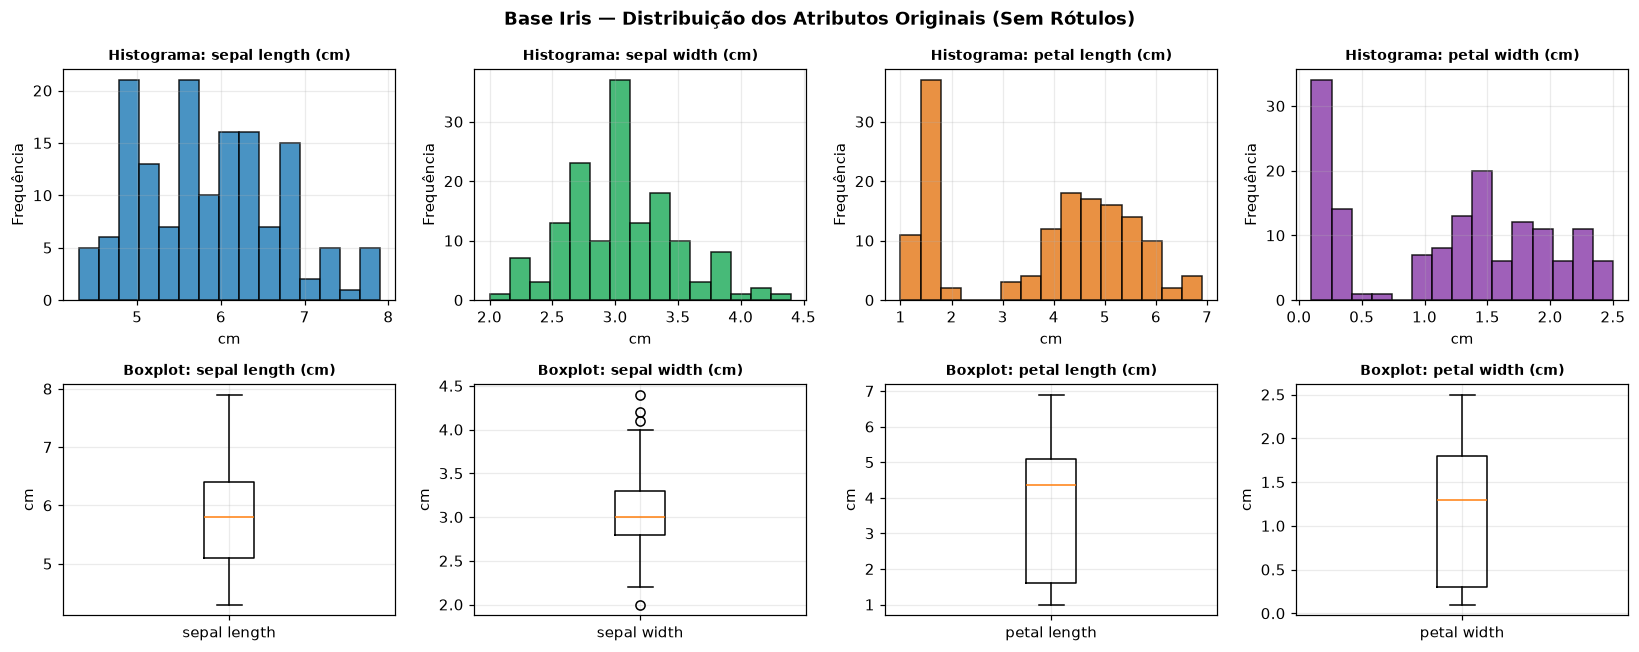

Estatísticas após padronização Z-score (média ~ 0 e desvio padrão ~ 1):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,-0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.87,-2.43,-1.57,-1.45
25%,-0.90,-0.59,-1.23,-1.18
50%,-0.05,-0.13,0.34,0.13
75%,0.67,0.56,0.76,0.79
max,2.49,3.09,1.79,1.71


In [24]:
# Padronização Z-score (Aula 01)
scaler_iris = StandardScaler()
X_iris_scaled = pd.DataFrame(
    scaler_iris.fit_transform(X_iris_raw),
    columns=X_iris_raw.columns
)

# Visualização das distribuições originais (Histogramas e Boxplots — Aula 04)
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
cores_iris = ['#2980b9', '#27ae60', '#e67e22', '#8e44ad']

for idx, col in enumerate(X_iris_raw.columns):
    axes[0, idx].hist(X_iris_raw[col], bins=15, color=cores_iris[idx], edgecolor='black', alpha=0.85)
    axes[0, idx].set_title(f'Histograma: {col}', fontsize=9, fontweight='bold')
    axes[0, idx].set_xlabel('cm')
    axes[0, idx].set_ylabel('Frequência')

    axes[1, idx].boxplot(X_iris_raw[col], tick_labels=[col.replace(' (cm)', '')])
    axes[1, idx].set_title(f'Boxplot: {col}', fontsize=9, fontweight='bold')
    axes[1, idx].set_ylabel('cm')

plt.suptitle('Base Iris — Distribuição dos Atributos Originais (Sem Rótulos)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('Estatísticas após padronização Z-score (média ~ 0 e desvio padrão ~ 1):')
display(X_iris_scaled.describe().round(2))

> 📌 **Leitura Exploratória (*Iris*):**  
> Os histogramas das dimensões da pétala (`petal length` e `petal width`) evidenciam uma **estrutura bimodal clara** (um agrupamento bem separado em valores menores e uma nuvem contínua mais extensa em valores maiores), enquanto as medidas de sépala apresentam distribuições mais sobrepostas. Após a padronização Z-score, todas as quatro variáveis passam a ter média $0$ e desvio padrão $1$.

---

## 2. Parametrização na Base *Iris*: Técnica do Joelho e Validação Interna (`K-Means` vs. `Bisecting K-Means`)

Executamos a varredura de $k \in \{2, 3, \dots, 10\}$ utilizando `KMeans` (particional) e `BisectingKMeans` (hierárquico divisivo) sobre `X_iris_scaled`, comparando quatro critérios de validação interna: **Inércia (WCSS)**, **Silhouette**, **Calinski-Harabasz** e **Davies-Bouldin**.

,Algoritmo,k,Inercia_WCSS,Silhouette,Calinski_Harabasz,Davies_Bouldin
0,K-Means,2,222.3617,0.5818,251.3493,0.5933
1,Bisecting K-Means,2,222.3617,0.5818,251.3493,0.5933
2,K-Means,3,139.8205,0.4599,241.9044,0.8336
3,Bisecting K-Means,3,139.8254,0.4594,241.8933,0.8340
4,K-Means,4,114.0925,0.3869,207.2659,0.8698
5,Bisecting K-Means,4,124.6790,0.4111,185.5348,1.0270
6,K-Means,5,90.9275,0.3459,202.9515,0.9483
7,Bisecting K-Means,5,98.9507,0.3362,183.5564,1.0254
8,K-Means,6,81.5444,0.3171,183.1091,1.0537
9,Bisecting K-Means,6,81.4966,0.3086,183.2334,1.0784


K-Means -> Melhor k por Silhouette: 2 | Calinski-Harabasz: 2 | Davies-Bouldin: 2
Bisecting K-Means -> Melhor k por Silhouette: 2 | Calinski-Harabasz: 2 | Davies-Bouldin: 2


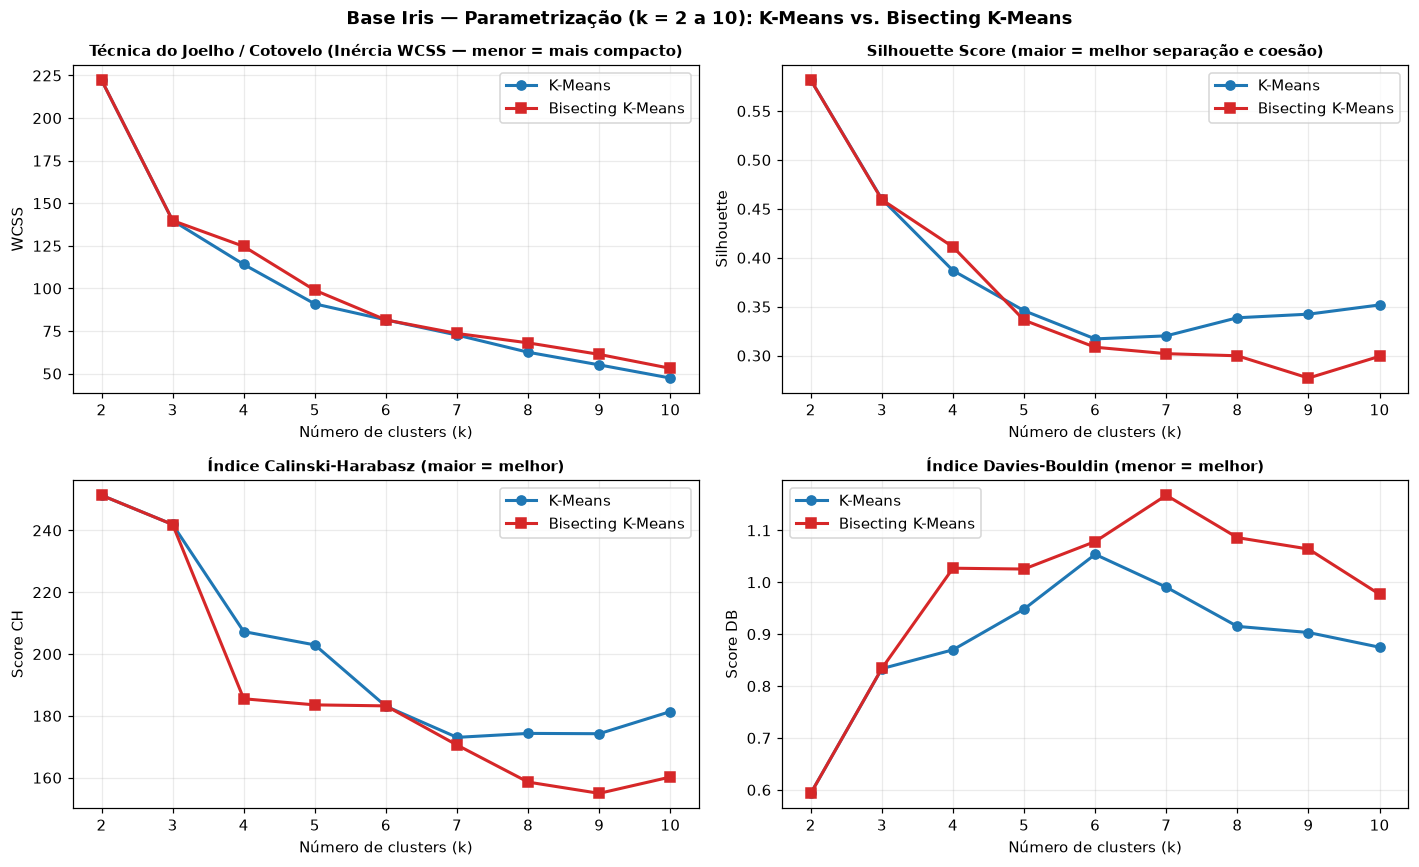

In [25]:
ks_iris = range(2, 11)
df_res_iris = rodar_varredura_k(X_iris_scaled, ks_iris, random_state=RANDOM_STATE)

display(df_res_iris.round(4))

# Resumo do melhor k indicado por cada critério interno
for alg in ['K-Means', 'Bisecting K-Means']:
    sub = df_res_iris[df_res_iris['Algoritmo'] == alg]
    k_sil = int(sub.loc[sub['Silhouette'].idxmax(), 'k'])
    k_ch = int(sub.loc[sub['Calinski_Harabasz'].idxmax(), 'k'])
    k_db = int(sub.loc[sub['Davies_Bouldin'].idxmin(), 'k'])
    print(f'{alg} -> Melhor k por Silhouette: {k_sil} | Calinski-Harabasz: {k_ch} | Davies-Bouldin: {k_db}')

plotar_curvas_k(df_res_iris, ks_iris, 'Base Iris — Parametrização (k = 2 a 10): K-Means vs. Bisecting K-Means')

> 📌 **Análise da Parametrização e Sensibilidade dos Critérios (*Iris*):**  
> - **Estrutura Geométrica (2 vs. 3 clusters):** Sem acesso aos rótulos, tanto o **Silhouette Score** (`0.5818` em $k=2$ vs. `0.4599` em $k=3$), quanto o **Calinski-Harabasz** (`251.35` em $k=2$ vs. `241.90` em $k=3$) e o **Davies-Bouldin** (`0.5933` em $k=2$ vs. `0.8336` em $k=3$) apontam unanimemente **$k=2$** como partição ótima em ambos os algoritmos. Na curva WCSS, observa-se a queda mais acentuada de $k=2$ (`222.36`) para $k=3$ (`139.82`), marcando um segundo cotovelo mais suave.  
> - **Sensibilidade à Escolha do Critério (Reflexão da Atividade):** Enquanto a **Inércia (WCSS)** cai monotonicamente e pode sugerir $k=3$ por inspeção visual do cotovelo secundário, os índices que equilibram coesão e separação (**Silhouette**, **CH** e **DB**) capturam a forte descontinuidade geométrica entre duas nuvens principais e cravam $k=2$.  
> - **K-Means vs. Bisecting K-Means:** Em $k=2$, ambos geram exatamente a mesma partição (WCSS `222.3617`, Silhouette `0.5818`). A partir de $k=3$ e especialmente em $k=4$ (WCSS `114.09` no `K-Means` vs. `124.68` no `Bisecting K-Means`), o `Bisecting K-Means` apresenta inércia ligeiramente maior por manter fixa a fronteira do corte anterior.

---

## 3. Agrupamento Hierárquico Aglomerativo (`Linkage Family`) na Base *Iris*

Aplicamos os algoritmos aglomerativos **Single-linkage**, **Complete-linkage**, **Average-linkage** e **Ward** sobre `X_iris_scaled`, avaliando a **Correlação Cofenética** (fidelidade do dendrograma às distâncias euclidianas originais), a visualização hierárquica nos dendrogramas e os cortes em $k=2$ e $k=3$.

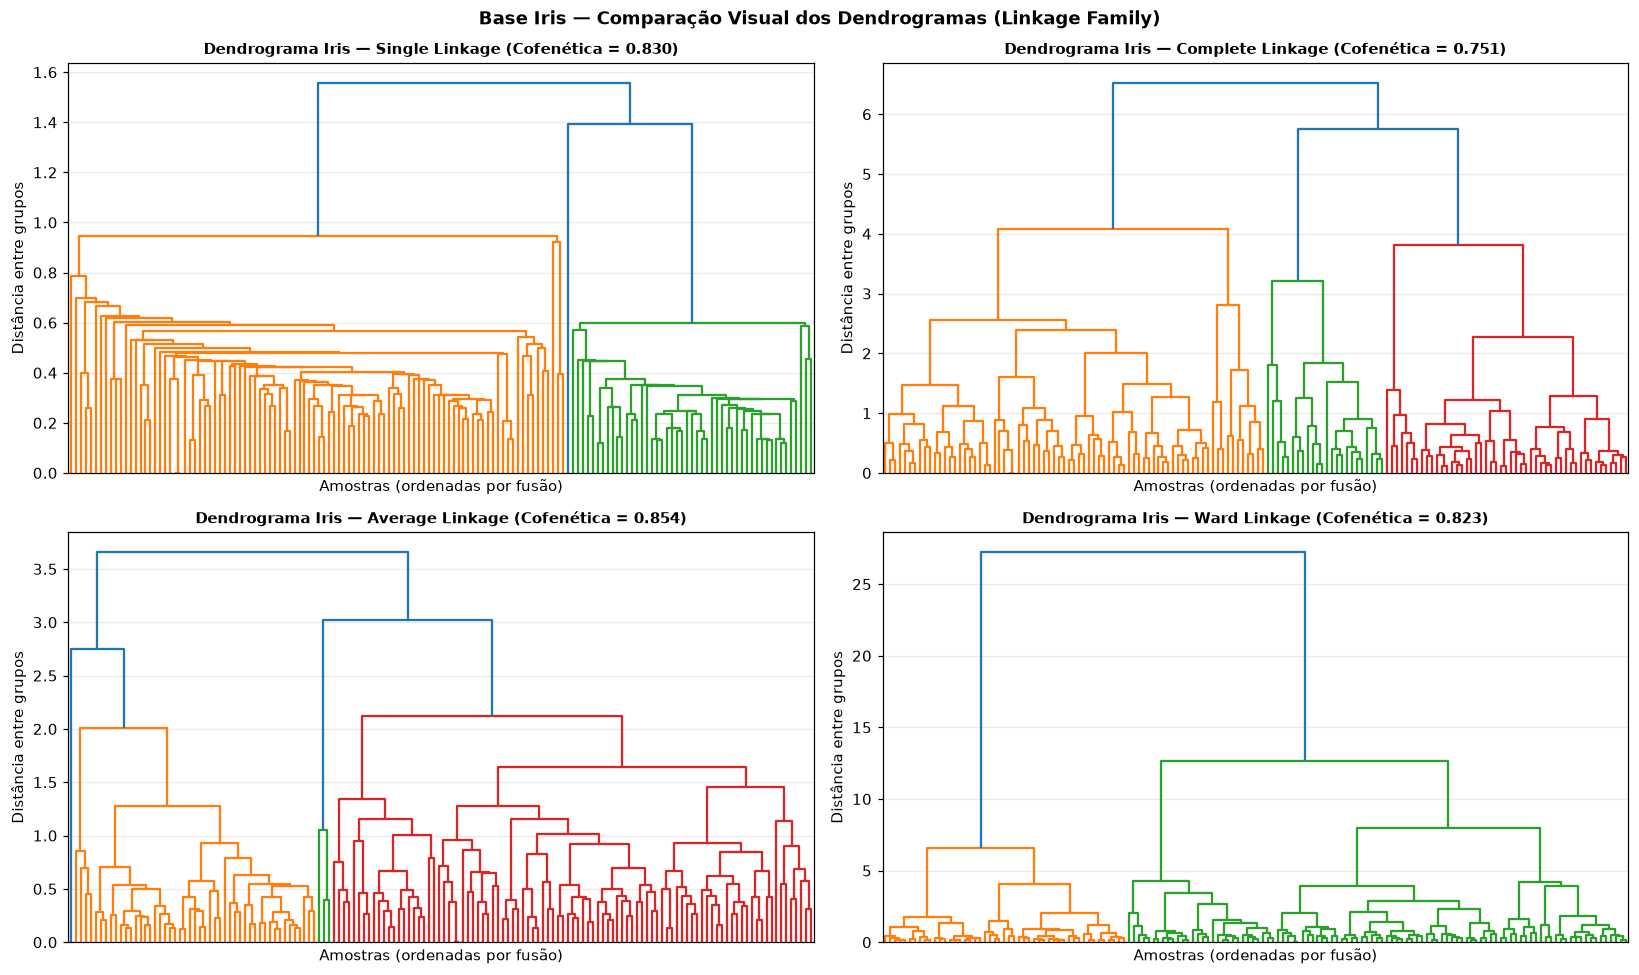

,Metodo,k,Cofenetica,Silhouette,Calinski_Harabasz,Davies_Bouldin,Tamanhos_Grupos
0,single,2,0.8300,0.5818,251.3493,0.5933,"{1: 100, 2: 50}"
1,single,3,0.8300,0.5046,131.5359,0.4929,"{1: 100, 2: 49, 3: 1}"
2,complete,2,0.7515,0.4408,151.6332,0.8927,"{1: 77, 2: 73}"
3,complete,3,0.7515,0.4496,213.0817,0.7584,"{1: 77, 2: 24, 3: 49}"
4,average,2,0.8544,0.5818,251.3493,0.5933,"{1: 50, 2: 100}"
5,average,3,0.8544,0.4803,149.0258,0.5753,"{1: 50, 2: 3, 3: 97}"
6,ward,2,0.8226,0.5770,240.2457,0.5917,"{1: 49, 2: 101}"
7,ward,3,0.8226,0.4467,222.7192,0.8035,"{1: 49, 2: 30, 3: 71}"


In [26]:
metodos_linkage = ['single', 'complete', 'average', 'ward']
dist_iris = pdist(X_iris_scaled, metric='euclidean')

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
lin_iris = {}
res_linkage_iris = []

for ax, metodo in zip(axes.flat, metodos_linkage):
    Z = linkage(X_iris_scaled, method=metodo)
    coph_corr, _ = cophenet(Z, dist_iris)
    lin_iris[metodo] = Z

    dendrogram(Z, no_labels=True, ax=ax)
    ax.set_title(f'Dendrograma Iris — {metodo.capitalize()} Linkage (Cofenética = {coph_corr:.3f})', fontsize=10, fontweight='bold')
    ax.set_xlabel('Amostras (ordenadas por fusão)')
    ax.set_ylabel('Distância entre grupos')

    for k in [2, 3]:
        labels_cut = fcluster(Z, t=k, criterion='maxclust')
        sil, ch, db = avaliar_particao(X_iris_scaled, labels_cut)
        tamanhos = pd.Series(labels_cut).value_counts().sort_index().to_dict()
        res_linkage_iris.append({
            'Metodo': metodo,
            'k': k,
            'Cofenetica': coph_corr,
            'Silhouette': sil,
            'Calinski_Harabasz': ch,
            'Davies_Bouldin': db,
            'Tamanhos_Grupos': str(tamanhos),
        })

plt.suptitle('Base Iris — Comparação Visual dos Dendrogramas (Linkage Family)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

df_lin_iris = pd.DataFrame(res_linkage_iris)
display(df_lin_iris.round(4))

> 📌 **Análise dos Dendrogramas e da Família *Linkage* (*Iris*):**  
> - **Single-linkage (Cofenética = `0.830`):** Em $k=2$, separa perfeitamente os blocos `{1: 100, 2: 50}` (Silhouette `0.5818`), mas em $k=3$ sofre do clássico ***chaining effect***, isolando **1 único ponto** (`{1: 100, 2: 49, 3: 1}`, derrubando o Calinski-Harabasz para `131.54`).  
> - **Average-linkage (Cofenética = `0.854` — maior fidelidade métrica):** Iguala o corte de `k=2` (`50` vs. `100`, Silhouette `0.5818`), porém em `k=3` ainda isola um pequeno subgrupo de 3 pontos (`{1: 50, 2: 3, 3: 97}`).  
> - **Ward (Cofenética = `0.823`) e Complete (Cofenética = `0.752`):** São os únicos da família `Linkage` que produzem 3 clusters de tamanho expressivo em $k=3$, com destaque para o **Ward** (`{1: 49, 2: 30, 3: 71}`, **CH = `222.72`** vs. `213.08` no `Complete`).

---

## 4. Projeção PCA 2D e Avaliação Indireta com os Rótulos Reais (*Iris*)

Conforme recomendado no roteiro da atividade (`PCA` + visualização 2D) e nas boas práticas de ML, reduzimos os 4 atributos padronizados para 2 componentes principais para comparar visualmente os agrupamentos obtidos ($k=2$ ótimo geométrico e $k=3$) contra as espécies reais (`y_iris_oculto`), reveladas **somente após o estudo preliminar**.

Variância explicada pelo PCA 2D (Iris): PC1 = 72.96% | PC2 = 22.85% | Total = 95.81%


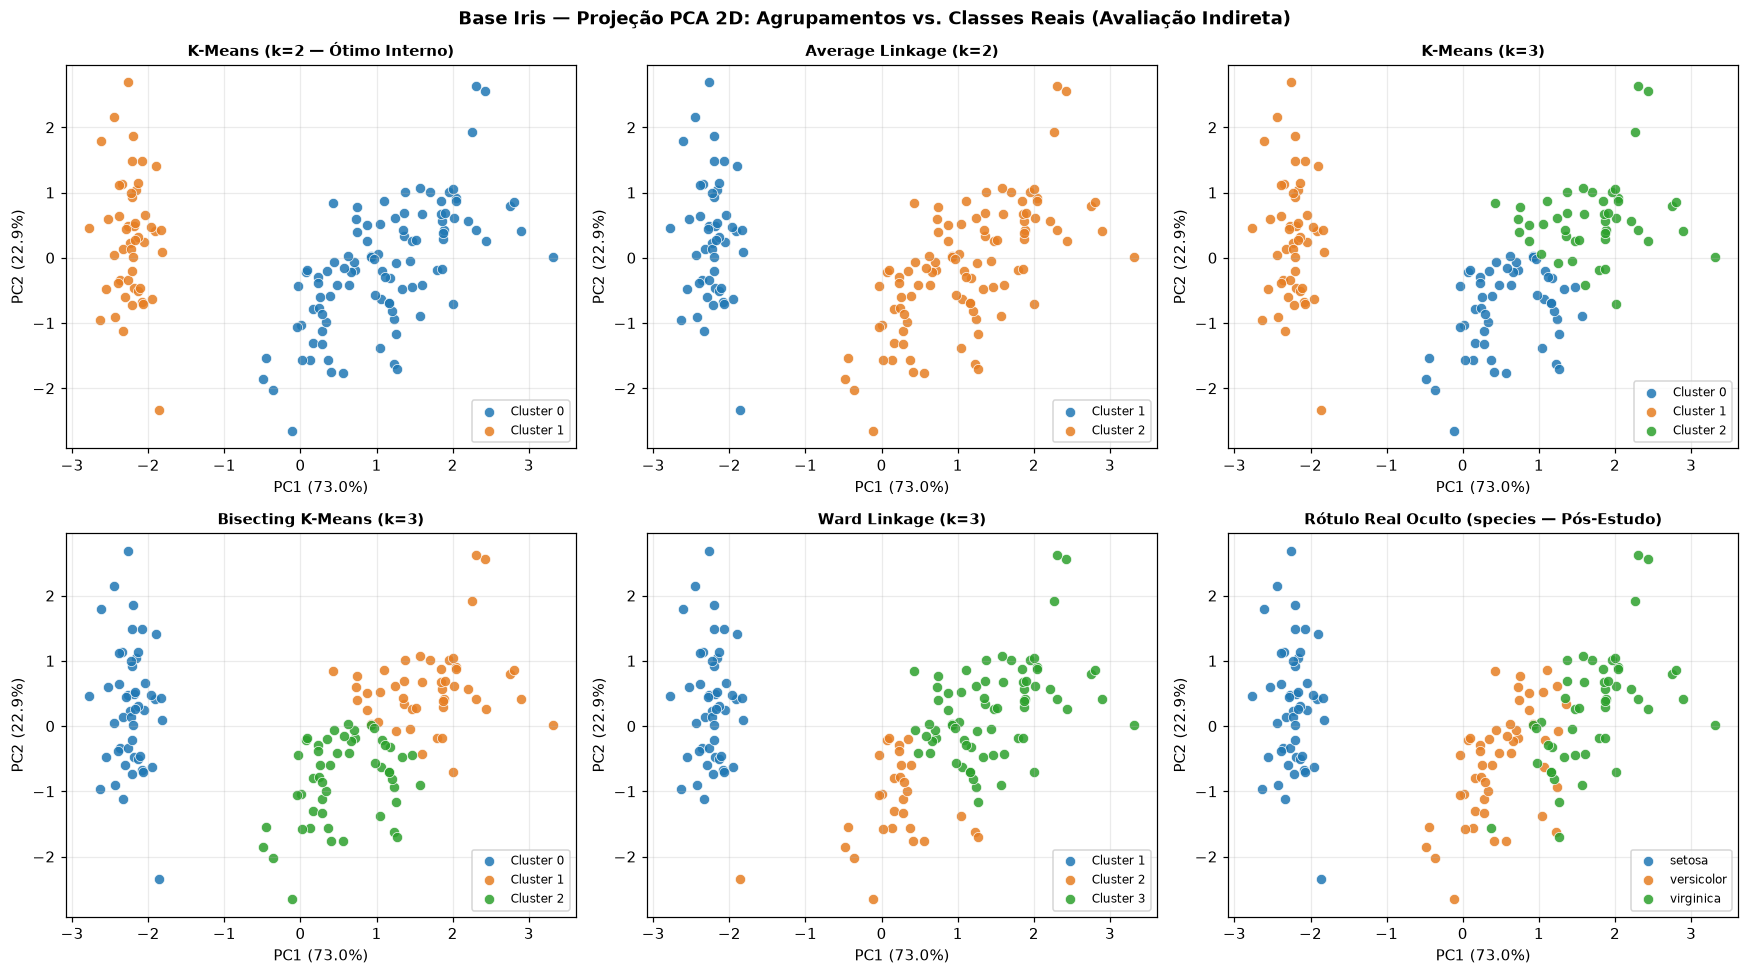

,Modelo,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI_vs_Species,NMI_vs_Species
0,K-Means (k=2),0.5818,251.3493,0.5933,0.5681,0.7337
1,Average Linkage (k=2),0.5818,251.3493,0.5933,0.5681,0.7337
2,Ward Linkage (k=2),0.5770,240.2457,0.5917,0.5438,0.6925
3,K-Means (k=3),0.4599,241.9044,0.8336,0.6201,0.6595
4,Bisecting K-Means (k=3),0.4594,241.8933,0.8340,0.6101,0.6526
5,Ward Linkage (k=3),0.4467,222.7192,0.8035,0.6153,0.6755


Concordância K-Means vs. Bisecting K-Means (k=3) — ARI: 0.9799

Matriz de Contingência: K-Means (k=2) vs. Espécie Real


target,setosa,versicolor,virginica
K-Means k=2,,,
0,0,50,50
1,50,0,0



Matriz de Contingência: K-Means (k=3) vs. Espécie Real


target,setosa,versicolor,virginica
K-Means k=3,,,
0,0,39,14
1,50,0,0
2,0,11,36


In [27]:
# Redução de dimensionalidade para 2D via PCA (apenas visualização)
pca_iris = PCA(n_components=2, random_state=RANDOM_STATE)
X_iris_pca = pca_iris.fit_transform(X_iris_scaled)
var_exp_iris = pca_iris.explained_variance_ratio_ * 100
print(f'Variância explicada pelo PCA 2D (Iris): PC1 = {var_exp_iris[0]:.2f}% | PC2 = {var_exp_iris[1]:.2f}% | Total = {var_exp_iris.sum():.2f}%')

km_iris_2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_iris_scaled)
km_iris_3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(X_iris_scaled)
bkm_iris_3 = BisectingKMeans(n_clusters=3, n_init=10, bisecting_strategy='biggest_inertia', random_state=RANDOM_STATE).fit_predict(X_iris_scaled)
avg_iris_2 = fcluster(lin_iris['average'], t=2, criterion='maxclust')
ward_iris_2 = fcluster(lin_iris['ward'], t=2, criterion='maxclust')
ward_iris_3 = fcluster(lin_iris['ward'], t=3, criterion='maxclust')

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
paineis_iris = [
    (km_iris_2, 'K-Means (k=2 — Ótimo Interno)', None),
    (avg_iris_2, 'Average Linkage (k=2)', None),
    (km_iris_3, 'K-Means (k=3)', None),
    (bkm_iris_3, 'Bisecting K-Means (k=3)', None),
    (ward_iris_3, 'Ward Linkage (k=3)', None),
    (y_iris_oculto, 'Rótulo Real Oculto (species — Pós-Estudo)', nomes_especies),
]

paleta_iris = ['#1f77b4', '#e67e22', '#2ca02c', '#9467bd']
for ax, (rotulos, titulo, mapa_nomes) in zip(axes.flat, paineis_iris):
    for i, v in enumerate(sorted(np.unique(rotulos))):
        mask = (rotulos == v)
        leg = mapa_nomes[v] if mapa_nomes else f'Cluster {v}'
        ax.scatter(
            X_iris_pca[mask, 0], X_iris_pca[mask, 1],
            s=45, alpha=0.85, color=paleta_iris[i % len(paleta_iris)],
            edgecolors='white', linewidth=0.5, label=leg
        )
    ax.set_title(titulo, fontsize=10, fontweight='bold')
    ax.set_xlabel(f'PC1 ({var_exp_iris[0]:.1f}%)')
    ax.set_ylabel(f'PC2 ({var_exp_iris[1]:.1f}%)')
    ax.legend(fontsize=8)

plt.suptitle('Base Iris — Projeção PCA 2D: Agrupamentos vs. Classes Reais (Avaliação Indireta)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Métricas externas indiretas (ARI e NMI) e matrizes de contingência
comparacao_ext_iris = []
for nome, labels in [
    ('K-Means (k=2)', km_iris_2),
    ('Average Linkage (k=2)', avg_iris_2),
    ('Ward Linkage (k=2)', ward_iris_2),
    ('K-Means (k=3)', km_iris_3),
    ('Bisecting K-Means (k=3)', bkm_iris_3),
    ('Ward Linkage (k=3)', ward_iris_3),
]:
    sil, ch, db = avaliar_particao(X_iris_scaled, labels)
    comparacao_ext_iris.append({
        'Modelo': nome,
        'Silhouette': sil,
        'Calinski_Harabasz': ch,
        'Davies_Bouldin': db,
        'ARI_vs_Species': adjusted_rand_score(y_iris_oculto, labels),
        'NMI_vs_Species': normalized_mutual_info_score(y_iris_oculto, labels),
    })

display(pd.DataFrame(comparacao_ext_iris).round(4))
print(f'Concordância K-Means vs. Bisecting K-Means (k=3) — ARI: {adjusted_rand_score(km_iris_3, bkm_iris_3):.4f}')

print('\nMatriz de Contingência: K-Means (k=2) vs. Espécie Real')
display(pd.crosstab(pd.Series(km_iris_2, name='K-Means k=2'), y_iris_oculto.map(nomes_especies)))
print('\nMatriz de Contingência: K-Means (k=3) vs. Espécie Real')
display(pd.crosstab(pd.Series(km_iris_3, name='K-Means k=3'), y_iris_oculto.map(nomes_especies)))

> 📌 **Conclusão Parcial da Base *Iris* (Reflexões do Enunciado):**  
> 1. **Por que a geometria indica 2 grupos embora existam 3 classes?** A projeção PCA 2D retém **`95,81%` da variância total** (`PC1 = 72,96%`, `PC2 = 22,85%`) e mostra visualmente que *Iris setosa* (`50` flores) forma um grupo totalmente isolado à esquerda, enquanto *versicolor* e *virginica* sobrepõem-se à direita. Na matriz de contingência de `K-Means (k=2)`, o Cluster 1 recupera `50/50` *setosa* (`NMI = 0,7337`).  
> 2. **Comparação K-Means vs. Bisecting K-Means ($k=3$):** Ambos alcançam altíssima concordância entre si (**ARI = `0,9799`**), porém o `K-Means` supera ligeiramente em Silhouette (`0,4599` vs. `0,4594`) e alinhamento externo (**ARI vs. species = `0,6201`** contra `0,6101` no `Bisecting K-Means` e `0,6153` no `Ward Linkage`), alocando `39/50` *versicolor* no Cluster 0 e `36/50` *virginica* no Cluster 2.  
> 3. **Melhor algoritmo na *Iris*:** **`K-Means`** (com **`Ward Linkage`** muito próximo como melhor representante hierárquico para $k=3$ e **`Average Linkage`** idêntico ao `K-Means` em $k=2$).

---

# Parte II — Base Principal Escolhida: *Tech Salaries*

## 5. Coleta, Dicionário de Dados e Diagnóstico Inicial (*Aula 00 e Aula 01*)

Carregamos a base `data/tech_salaries.csv` e o dicionário `data/data_dictionary.csv` para inspecionar dimensões, tipos de atributos e estruturar o plano de tratamento de dados antes de qualquer modelagem.

In [28]:
# Leitura da base escolhida (Tech Salaries) e do dicionário de dados
df_raw = pd.read_csv('data/tech_salaries.csv')
df_dict = pd.read_csv('data/data_dictionary.csv')

print(f'Total de profissionais registrados: {df_raw.shape[0]:,}'.replace(',', '.'))
print(f'Total de características analisadas (colunas): {df_raw.shape[1]}')

display(df_dict)
display(df_raw.head())
df_raw.info()

Total de profissionais registrados: 28.000
Total de características analisadas (colunas): 16


,column,dtype,description
0,employee_id,string,Unique employee identifier.
1,level,string,"Career level: L3_entry, L4, L5_senior, L6_staf..."
2,years_experience,float,Total years of professional experience.
3,company_tier,string,"ai_lab, quant_hft, faang, high_growth_public, ..."
4,location,string,"sf_bay, nyc, seattle, other_us_metro, us_lcol,..."
5,specialization,string,"ml_ai, backend, infra, data, frontend, securit..."
6,education,string,"bachelors, masters, phd, bootcamp, self_taught."
7,company_size,string,"Headcount band: <50, 50-500, 500-5k, 5k-50k, >..."
8,remote,int,1 if primarily remote.
9,num_competing_offers,int,Number of competing offers held during negotia...


,employee_id,level,years_experience,company_tier,location,specialization,education,company_size,remote,num_competing_offers,negotiated,base_salary_usd,bonus_usd,equity_annual_usd,total_comp_usd,high_earner
0,E000000,L3_entry,6.1,faang,india,data,phd,50-500,0,0,0,29500,6200,25800,61500,0
1,E000001,L5_senior,7.5,high_growth_public,seattle,data,bachelors,500-5k,0,1,1,65300,13600,57100,136000,0
2,E000002,L4,5.0,quant_hft,sf_bay,backend,phd,<50,1,0,1,151000,194100,86300,431400,0
3,E000003,L4,6.3,startup_late,sf_bay,data,bachelors,<50,0,1,1,297200,20600,94900,412800,0
4,E000004,L4,8.8,high_growth_public,europe,data,bachelors,500-5k,0,1,1,84800,17700,74200,176700,0


<class 'pandas.DataFrame'>
RangeIndex: 28000 entries, 0 to 27999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           28000 non-null  str    
 1   level                 28000 non-null  str    
 2   years_experience      28000 non-null  float64
 3   company_tier          28000 non-null  str    
 4   location              28000 non-null  str    
 5   specialization        28000 non-null  str    
 6   education             28000 non-null  str    
 7   company_size          28000 non-null  str    
 8   remote                28000 non-null  int64  
 9   num_competing_offers  28000 non-null  int64  
 10  negotiated            28000 non-null  int64  
 11  base_salary_usd       28000 non-null  int64  
 12  bonus_usd             28000 non-null  int64  
 13  equity_annual_usd     28000 non-null  int64  
 14  total_comp_usd        28000 non-null  int64  
 15  high_earner           28000 no

> 📌 **Classificação Estatística das Variáveis (Aula 00) e Papel na Clusterização:**  
> - **Identificador (Remover):** `employee_id` (código único sem significado métrico para agrupamento).  
> - **Qualitativas Ordinais (`OrdinalEncoder`):** `level` (`L3_entry` $\to$ `L7_principal`), `education` (`self_taught` $\to$ `phd`) e `company_size` (`<50` $\to$ `>50k`).  
> - **Qualitativas Nominais (`OneHotEncoder`):** `company_tier`, `location` e `specialization`.  
> - **Quantitativas Contínuas e Discretas (`StandardScaler`):** `years_experience`, `num_competing_offers`, `remote` (binária), `negotiated` (binária), `base_salary_usd`, `bonus_usd` e `equity_annual_usd`.  
> - **Rótulos / Targets (Omitir do Agrupamento!):** `total_comp_usd` (*TARGET contínuo*) e `high_earner` (*TARGET binário — top 10%*). Conforme a nota de rodapé 1 do enunciado, ambos serão **excluídos do treinamento** e consultados apenas de forma indireta na avaliação final dos clusters.

---

## 6. Auditoria de Qualidade, Limpeza e Detecção de Outliers (*Aula 01, Aula 02 e Projeto Dog*)

Realizamos o diagnóstico completo de **dados faltantes**, **registros duplicados**, **inconsistências lógicas de negócio** e **consistência contábil** entre os componentes salariais e a compensação total.

In [29]:
# 6.1 Auditoria de dados ausentes
nulos = df_raw.isnull().sum()
perc_nulos = (df_raw.isnull().mean() * 100).round(2)
tabela_nulos = pd.DataFrame({'Valores Nulos': nulos, 'Percentual (%)': perc_nulos})
print('Diagnóstico de valores ausentes:')
display(tabela_nulos[tabela_nulos['Valores Nulos'] > 0] if (nulos > 0).any() else tabela_nulos)

# 6.2 Auditoria de duplicados (linhas completas e chave primária)
print('Linhas totalmente duplicadas:', df_raw.duplicated().sum())
print('IDs duplicados (employee_id):', df_raw['employee_id'].duplicated().sum())

# 6.3 Regras de negócio e inconsistências lógicas
print('Experiência negativa (< 0):', (df_raw['years_experience'] < 0).sum())
print('Salário base inválido (<= 0):', (df_raw['base_salary_usd'] <= 0).sum())
print('Bônus negativo (< 0):', (df_raw['bonus_usd'] < 0).sum())
print('Equity negativo (< 0):', (df_raw['equity_annual_usd'] < 0).sum())
print('Ofertas concorrentes fora de [0, 3]:', ((df_raw['num_competing_offers'] < 0) | (df_raw['num_competing_offers'] > 3)).sum())
print('Flags binárias fora de {0, 1}:', (
    ~df_raw['remote'].isin([0, 1]) | ~df_raw['negotiated'].isin([0, 1]) | ~df_raw['high_earner'].isin([0, 1])
).sum())

# 6.4 Verificação de consistência contábil da remuneração total e valores únicos categóricos
soma_comp = df_raw['base_salary_usd'] + df_raw['bonus_usd'] + df_raw['equity_annual_usd']
diff_comp = (df_raw['total_comp_usd'] - soma_comp).abs()
print(f'Diferença média |total_comp - (base + bonus + equity)|: ${diff_comp.mean():.2f} | Máxima: ${diff_comp.max():.2f}')

for c in ['level', 'company_tier', 'location', 'specialization', 'education', 'company_size']:
    print(f"Categorias em {c} ({df_raw[c].nunique()}): {sorted(df_raw[c].unique().tolist())}")

Diagnóstico de valores ausentes:


,Valores Nulos,Percentual (%)
employee_id,0,0.0
level,0,0.0
years_experience,0,0.0
company_tier,0,0.0
location,0,0.0
specialization,0,0.0
education,0,0.0
company_size,0,0.0
remote,0,0.0
num_competing_offers,0,0.0


Linhas totalmente duplicadas: 0
IDs duplicados (employee_id): 0
Experiência negativa (< 0): 0
Salário base inválido (<= 0): 0
Bônus negativo (< 0): 0
Equity negativo (< 0): 0
Ofertas concorrentes fora de [0, 3]: 0
Flags binárias fora de {0, 1}: 0
Diferença média |total_comp - (base + bonus + equity)|: $26.81 | Máxima: $100.00
Categorias em level (5): ['L3_entry', 'L4', 'L5_senior', 'L6_staff', 'L7_principal']
Categorias em company_tier (8): ['ai_lab', 'bank', 'faang', 'high_growth_public', 'mid_tier', 'quant_hft', 'startup_early', 'startup_late']
Categorias em location (8): ['europe', 'india', 'nyc', 'other_us_metro', 'remote_us', 'seattle', 'sf_bay', 'us_lcol']
Categorias em specialization (7): ['backend', 'data', 'frontend', 'infra', 'ml_ai', 'mobile', 'security']
Categorias em education (5): ['bachelors', 'bootcamp', 'masters', 'phd', 'self_taught']
Categorias em company_size (5): ['50-500', '500-5k', '5k-50k', '<50', '>50k']


> 📌 **Leitura da Auditoria de Qualidade:**  
> - **Completude e Unicidade:** Confirmados **0 valores nulos** em todas as 16 colunas, **0 linhas duplicadas** e **0 IDs repetidos** nos **28.000** registros.  
> - **Regras de Domínio:** Zero ocorrências inválidas (sem experiência, salário, bônus ou *equity* negativos, `num_competing_offers` estritamente em `[0, 3]` e flags binárias íntegras em `{0, 1}`).  
> - **Consistência Contábil:** A diferença média entre `total_comp_usd` e a soma `(base + bonus + equity)` foi de apenas **\$26,81** (máxima de **\$100,00** por arredondamento).

A seguir, aplicamos a etapa preventiva de **limpeza/padronização textual** (criando `df_clean`), isolamos os rótulos (`targets_ocultos`) e avaliamos **dados discrepantes (*outliers*)** por dois critérios vistos em aula: **IQR ($1.5 \times \text{IQR}$)** e **Escore Z ($|z| > 2$ e $|z| > 3$)** (Aula 02).

In [30]:
# Cópia segura da base bruta (preservando df_raw)
df_clean = df_raw.copy()

# Padronização textual (Aula 01: remoção de espaços extras) e eliminação preventiva de duplicados
cols_categoricas = ['level', 'company_tier', 'location', 'specialization', 'education', 'company_size']
for c in cols_categoricas:
    df_clean[c] = df_clean[c].astype(str).str.strip()

df_clean = df_clean.drop_duplicates(subset=['employee_id']).reset_index(drop=True)

# Tratamento preventivo de eventuais nulos (mediana para numéricas, moda para categóricas)
if df_clean.isnull().any().any():
    for col in df_clean.select_dtypes(include=[np.number]).columns:
        if df_clean[col].isnull().any():
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
    for col in cols_categoricas:
        if df_clean[col].isnull().any():
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode().iloc[0])

# Isolamento estrito de ID e Targets para não contaminar os algoritmos não-supervisionados
ids_funcionarios = df_clean['employee_id'].copy()
targets_ocultos = df_clean[['total_comp_usd', 'high_earner']].copy()

# Diagnóstico de Outliers: IQR (1.5 * IQR) e Escore Z (|z| > 2 e |z| > 3 — Aula 02)
cols_num_diag = ['years_experience', 'base_salary_usd', 'bonus_usd', 'equity_annual_usd', 'total_comp_usd']
diag_outliers = []
for col in cols_num_diag:
    s = df_clean[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((s < lim_inf) | (s > lim_sup)).sum())
    z = (s - s.mean()) / s.std()
    diag_outliers.append({
        'Variavel': col,
        'Lim_Inf_IQR': round(lim_inf, 2),
        'Lim_Sup_IQR': round(lim_sup, 2),
        'Outliers_IQR': n_iqr,
        'Outliers_IQR_%': round(n_iqr / len(df_clean) * 100, 2),
        'Incomuns_|Z|>2': int((z.abs() > 2).sum()),
        'Extremos_|Z|>3': int((z.abs() > 3).sum()),
    })

print(f'Base limpa pronta: {len(df_clean):,} registros únicos.'.replace(',', '.'))
display(pd.DataFrame(diag_outliers))

Base limpa pronta: 28.000 registros únicos.


,Variavel,Lim_Inf_IQR,Lim_Sup_IQR,Outliers_IQR,Outliers_IQR_%,Incomuns_|Z|>2,Extremos_|Z|>3
0,years_experience,-9.85,21.75,107,0.38,1138,88
1,base_salary_usd,-83150.00,331650.00,1352,4.83,1266,515
2,bonus_usd,-32687.50,81412.50,3224,11.51,1078,592
3,equity_annual_usd,-78700.00,213300.00,1633,5.83,1347,554
4,total_comp_usd,-181487.50,633412.50,1515,5.41,1221,501


> 📌 **Decisão Metodológica sobre *Outliers* em Dados Salariais:**  
> Os diagnósticos apontam `11,51%` de outliers por IQR em `bonus_usd` (`3.224` casos acima de \$81.412,50), `5,83%` em `equity_annual_usd` (`1.633` casos) e `4,83%` em `base_salary_usd` (`1.352` casos), além de `501` registros com $|Z| > 3$ em `total_comp_usd`. Diferente de erros de sensor (como `idade = -10` na Aula 01), esses valores representam **fenômenos reais do mercado** (perfis `L7_principal`, `ai_lab` ou `quant_hft`).  
> - **Por que preservar em vez de remover ou truncar (*clipping*)?** Em *clustering*, esses extremos constituem sinal legítimo de segmentos de altíssima remuneração.  
> - Para lidar com as escalas e caudas longas sem descartar dados, usaremos **Z-score (`StandardScaler`)** como padrão e compararemos sua sensibilidade frente a **`RobustScaler`** e **`MinMaxScaler`** (Aula 01, slide 33).

---

## 7. Medidas Descritivas, Separatrizes e Visualização (*Aulas 02, 03 e 04*)

Calculamos as medidas de tendência central (média, mediana, moda), dispersão (desvio padrão, amplitude), separatrizes ($Q_1$, $Q_3$, e o **9º Decil $P_{90}$**) e construímos **tabelas de distribuição de frequências** (`Fi`, `Fri (%)`, `Fac`, `Frac (%)`).

In [31]:
# 7.1 Medidas Descritivas e Separatrizes (Aula 02)
cols_desc = ['years_experience', 'num_competing_offers', 'base_salary_usd', 'bonus_usd', 'equity_annual_usd', 'total_comp_usd']
tabela_desc_tech = pd.DataFrame({
    'Média': df_clean[cols_desc].mean(),
    'Mediana': df_clean[cols_desc].median(),
    'Moda': [df_clean[c].mode().iloc[0] for c in cols_desc],
    'Desvio Padrão': df_clean[cols_desc].std(),
    'Amplitude': df_clean[cols_desc].max() - df_clean[cols_desc].min(),
    'Q1 (P25)': df_clean[cols_desc].quantile(0.25),
    'Q3 (P75)': df_clean[cols_desc].quantile(0.75),
    'P90 (Decil 9)': df_clean[cols_desc].quantile(0.90),
    'Mínimo': df_clean[cols_desc].min(),
    'Máximo': df_clean[cols_desc].max(),
}).round(2)

print('Medidas Descritivas e Separatrizes (Tech Salaries):')
display(tabela_desc_tech)

# Conexão do 9º Decil (Aula 02) com o target binário high_earner
print(
    f"Proporção de high_earner == 1: {df_clean['high_earner'].mean() * 100:.2f}% | "
    f"Menor total_comp_usd entre high_earner == 1: ${df_clean.loc[df_clean['high_earner'] == 1, 'total_comp_usd'].min():,}"
)

# 7.2 Tabela de Distribuição de Frequências — Fi, Fri (%), Fac, Frac (%) (Aula 03)
def tabela_frequencia(serie, ordem=None):
    contagem = serie.value_counts()
    if ordem is not None:
        contagem = contagem.reindex([x for x in ordem if x in contagem.index])
    df_freq = pd.DataFrame({'Fi': contagem})
    df_freq['Fri (%)'] = (df_freq['Fi'] / df_freq['Fi'].sum() * 100).round(2)
    df_freq['Fac'] = df_freq['Fi'].cumsum()
    df_freq['Frac (%)'] = df_freq['Fri (%)'].cumsum().round(2)
    return df_freq

print('\nTabela de Frequências — Nível de Carreira (level):')
display(tabela_frequencia(df_clean['level'], ordem=['L3_entry', 'L4', 'L5_senior', 'L6_staff', 'L7_principal']))

print('\nTabela de Frequências — Tipo de Empresa (company_tier):')
display(tabela_frequencia(df_clean['company_tier']))

Medidas Descritivas e Separatrizes (Tech Salaries):


,Média,Mediana,Moda,Desvio Padrão,Amplitude,Q1 (P25),Q3 (P75),P90 (Decil 9),Mínimo,Máximo
years_experience,6.42,5.7,0.0,5.20,29.9,2.0,9.9,13.8,0.0,29.9
num_competing_offers,0.84,1.0,0.0,0.91,3.0,0.0,1.0,2.0,0.0,3.0
base_salary_usd,139112.89,113500.0,21700.0,99078.24,1647500.0,72400.0,176100.0,260700.0,16800.0,1664300.0
bonus_usd,41235.06,19400.0,3500.0,73015.06,2138000.0,10100.0,38625.0,92310.0,1800.0,2139800.0
equity_annual_usd,80195.58,55900.0,9800.0,75123.42,1020200.0,30800.0,103800.0,172200.0,3500.0,1023700.0
total_comp_usd,260543.76,203500.0,35000.0,211310.08,4720100.0,124100.0,327825.0,501410.0,35000.0,4755100.0


Proporção de high_earner == 1: 10.00% | Menor total_comp_usd entre high_earner == 1: $501,500

Tabela de Frequências — Nível de Carreira (level):


,Fi,Fri (%),Fac,Frac (%)
level,,,,
L3_entry,7280,26.00,7280,26.00
L4,8407,30.02,15687,56.02
L5_senior,6774,24.19,22461,80.21
L6_staff,3840,13.71,26301,93.92
L7_principal,1699,6.07,28000,99.99



Tabela de Frequências — Tipo de Empresa (company_tier):


,Fi,Fri (%),Fac,Frac (%)
company_tier,,,,
mid_tier,6731,24.04,6731,24.04
faang,5608,20.03,12339,44.07
high_growth_public,3949,14.10,16288,58.17
startup_late,3378,12.06,19666,70.23
startup_early,2757,9.85,22423,80.08
bank,2743,9.80,25166,89.88
ai_lab,1462,5.22,26628,95.10
quant_hft,1372,4.90,28000,100.00


> 📌 **Leitura Estatística (Aula 02 e Aula 03):**  
> - **Assimetria à Direita (Distribuição de Renda):** Conforme destacado na Aula 02 (slide 10), a média supera consistentemente a mediana em todos os componentes salariais: salário base (**\$139.112,89** vs. **\$113.500,00**), bônus (**\$41.235,06** vs. **\$19.400,00**, com desvio padrão de **\$73.015,06**) e *equity* (**\$80.195,58** vs. **\$55.900,00**). A mediana reflete melhor o profissional típico da base.  
> - **Separatriz ($D_9 / P_{90}$):** O 9º decil de `total_comp_usd` é **\$501.410,00**, coincidindo exatamente com o piso observado de **\$501.500** que define os `10,00%` classificados como `high_earner == 1`.  
> - **Tabelas de Frequência:** `L4` (`30,02%`), `L3_entry` (`26,00%`) e `L5_senior` (`24,19%`) somam `80,21%` da amostra por nível; em `company_tier`, `mid_tier` (`24,04%`) e `faang` (`20,03%`) lideram, enquanto `ai_lab` (`5,22%`) e `quant_hft` (`4,90%`) são nichos minoritários — reforçando a necessidade de amostragem estratificada.

Em seguida, geramos os **histogramas** das principais variáveis numéricas para visualizar a forma e assimetria das distribuições.

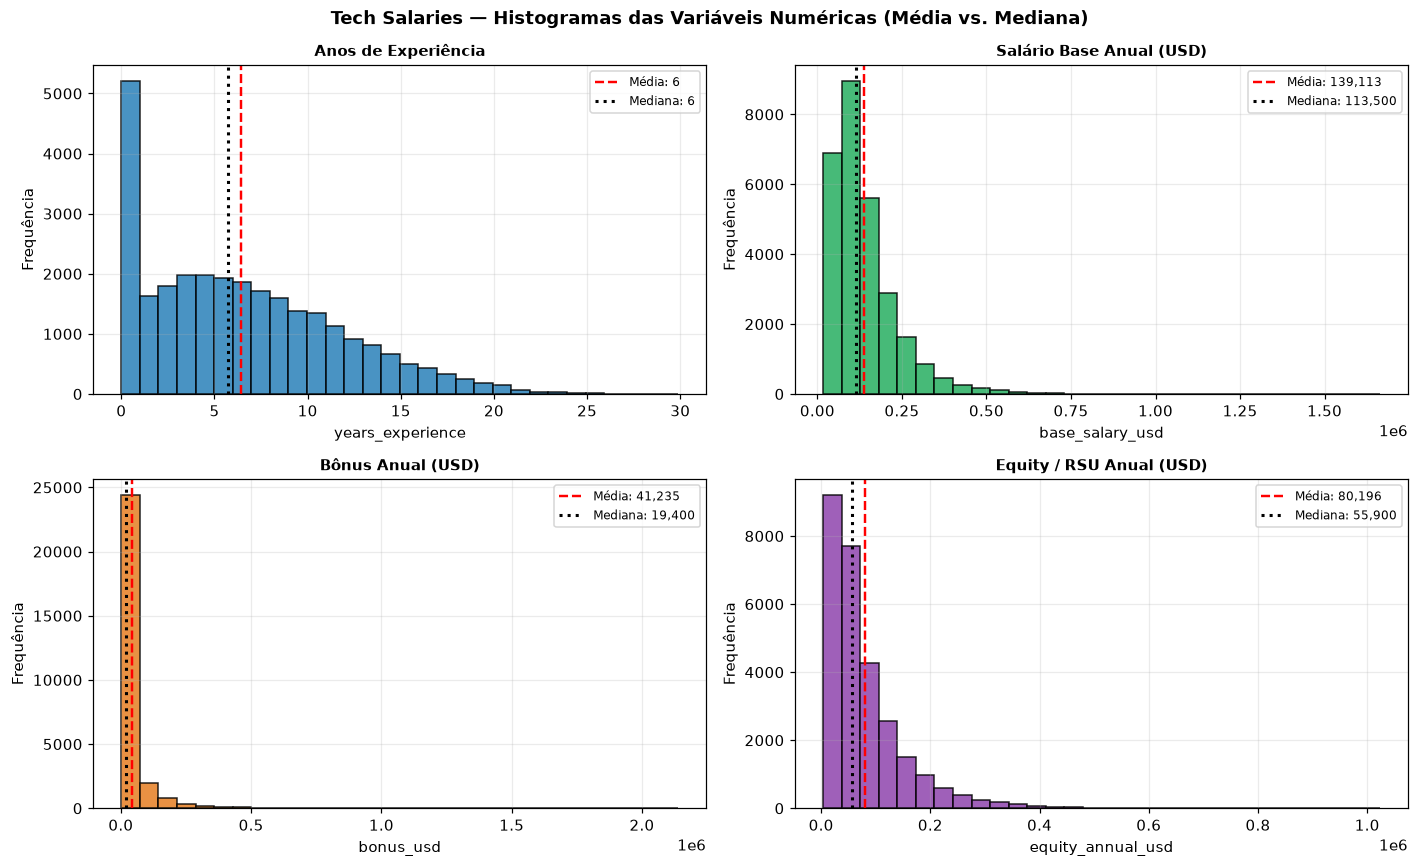

In [32]:
# 7.3 Histogramas das variáveis numéricas (forma da distribuição — Aula 04)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
hist_vars = [
    ('years_experience', 'Anos de Experiência', '#2980b9'),
    ('base_salary_usd', 'Salário Base Anual (USD)', '#27ae60'),
    ('bonus_usd', 'Bônus Anual (USD)', '#e67e22'),
    ('equity_annual_usd', 'Equity / RSU Anual (USD)', '#8e44ad'),
]

for ax, (col, titulo, cor) in zip(axes.flat, hist_vars):
    ax.hist(df_clean[col], bins=30, color=cor, edgecolor='black', alpha=0.85)
    ax.axvline(df_clean[col].mean(), color='red', linestyle='--', linewidth=1.6, label=f'Média: {df_clean[col].mean():,.0f}')
    ax.axvline(df_clean[col].median(), color='black', linestyle=':', linewidth=2.0, label=f'Mediana: {df_clean[col].median():,.0f}')
    ax.set_title(titulo, fontsize=10, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequência')
    ax.legend(fontsize=8)

plt.suptitle('Tech Salaries — Histogramas das Variáveis Numéricas (Média vs. Mediana)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

> 📌 **Interpretação dos Histogramas:**  
> Os histogramas confirmam visualmente a **assimetria positiva** nos componentes de remuneração (`base_salary_usd`, `bonus_usd` e `equity_annual_usd`), onde a linha tracejada da **média** desloca-se para a direita em relação à **mediana** (especialmente em bônus e equity, fortemente concentrados em segmentos específicos).

A seguir, utilizamos **boxplots**, **barras horizontais** (recomendadas na Aula 04 para rótulos categóricos textuais, partindo do zero) e **dispersão** entre experiência e salário base.

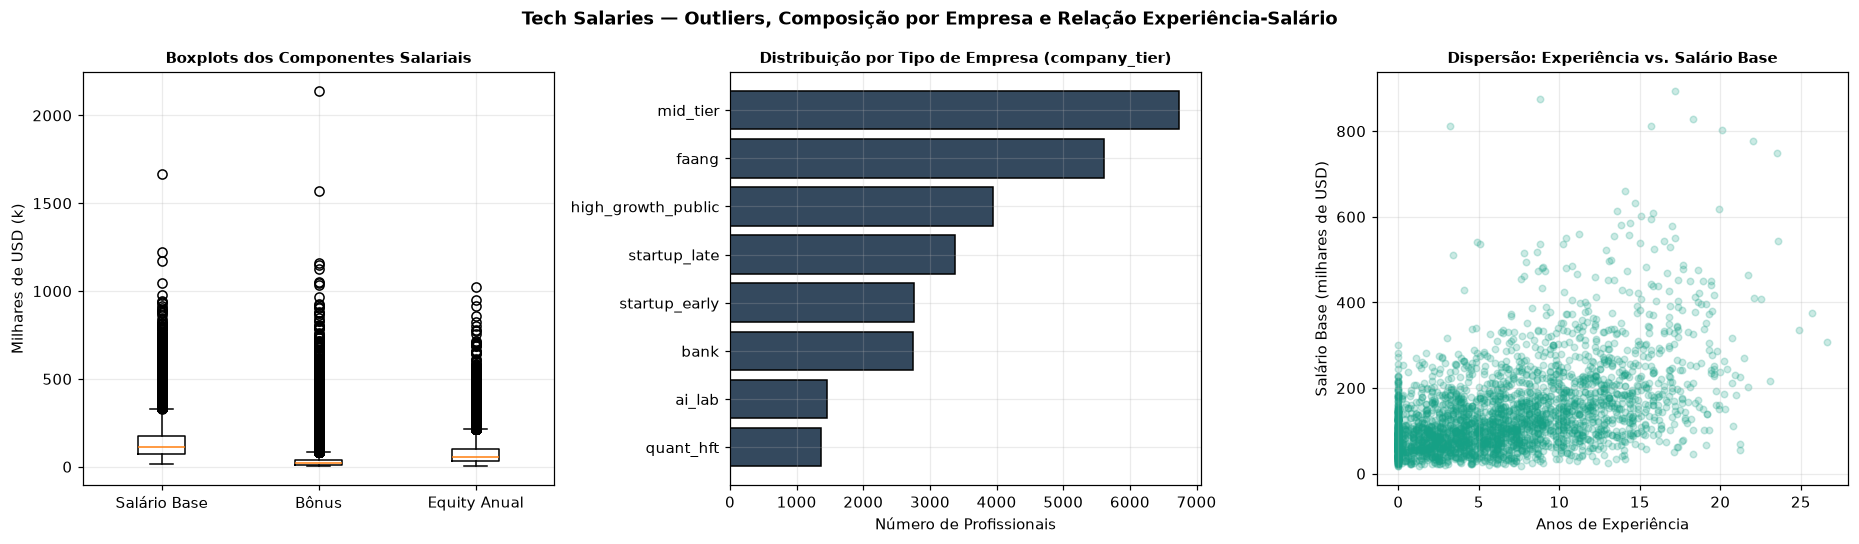

In [33]:
# 7.4 Boxplots, Barras Horizontais (base zero — Aula 04) e Dispersão
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Painel 1: Boxplots comparando os três componentes salariais
axes[0].boxplot(
    [df_clean['base_salary_usd'] / 1000, df_clean['bonus_usd'] / 1000, df_clean['equity_annual_usd'] / 1000],
    tick_labels=['Salário Base', 'Bônus', 'Equity Anual']
)
axes[0].set_title('Boxplots dos Componentes Salariais', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Milhares de USD (k)')

# Painel 2: Barras horizontais por company_tier (ordenado, eixo X iniciando em 0)
cont_tier = df_clean['company_tier'].value_counts().sort_values(ascending=True)
axes[1].barh(cont_tier.index, cont_tier.values, color='#34495e', edgecolor='black')
axes[1].set_xlim(left=0)
axes[1].set_title('Distribuição por Tipo de Empresa (company_tier)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Número de Profissionais')

# Painel 3: Dispersão Experiência vs. Salário Base
am_vis = df_clean.sample(n=min(3000, len(df_clean)), random_state=RANDOM_STATE)
axes[2].scatter(am_vis['years_experience'], am_vis['base_salary_usd'] / 1000, alpha=0.22, s=18, color='#16a085')
axes[2].set_title('Dispersão: Experiência vs. Salário Base', fontsize=10, fontweight='bold')
axes[2].set_xlabel('Anos de Experiência')
axes[2].set_ylabel('Salário Base (milhares de USD)')

plt.suptitle('Tech Salaries — Outliers, Composição por Empresa e Relação Experiência-Salário', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

> 📌 **Análise Visual das Relações e Discrepâncias:**  
> Os boxplots destacam numerosos pontos acima dos bigodes superiores em bônus e equity (evidenciando pacotes diferenciados de mercado). O gráfico de dispersão mostra tendência positiva entre anos de experiência e salário base, porém com ampla dispersão vertical para um mesmo tempo de carreira — sinal de que fatores categóricos (`company_tier`, `location`, `level`) exercem forte influência na formação dos grupos.

---

## 8. Amostragem Estatística (*Aleatória Simples vs. Estratificada* — Aula 01 e Projeto Dog)

Como a base possui **28.000 registros**, calcular a matriz completa de distâncias par a par do algoritmo hierárquico `linkage()` exigiria $\frac{28.000 \times 27.999}{2} \approx 392\text{ milhões}$ de distâncias (~3,1 GB apenas no vetor condensado, além de complexidade $O(N^2)$ a $O(N^3)$).  

Aplicamos o conceito de **Redução de Dados por Amostragem** (Aula 01, slides 20–28), comparando **Amostragem Aleatória Simples** e **Amostragem Estratificada por `company_tier`** ($n = 2.000$) para garantir representatividade fiel sem viés de amostragem. Enquanto `K-Means` e `Bisecting K-Means` serão executados nos **28.000 registros completos**, a amostra estratificada permitirá comparar todos os algoritmos (incluindo `Linkage`) de forma justa sobre exatamente os mesmos $2.000$ profissionais.

In [34]:
N_AMOSTRA = 2000

# Técnica 1: Amostragem Aleatória Simples
amostra_simples = df_clean.sample(n=N_AMOSTRA, random_state=RANDOM_STATE)

# Técnica 2: Amostragem Estratificada (preservando a proporção exata de cada company_tier)
amostra_estratificada, _ = train_test_split(
    df_clean,
    train_size=N_AMOSTRA,
    stratify=df_clean['company_tier'],
    random_state=RANDOM_STATE
)

# Comparação de proporções por estrato e de estatísticas salariais (População vs. Amostras)
comp_prop = pd.DataFrame({
    'População (%)': (df_clean['company_tier'].value_counts(normalize=True) * 100).round(2),
    'Amostra Simples (%)': (amostra_simples['company_tier'].value_counts(normalize=True) * 100).round(2),
    'Amostra Estratificada (%)': (amostra_estratificada['company_tier'].value_counts(normalize=True) * 100).round(2),
})
print('Comparação das Proporções por company_tier (%):')
display(comp_prop)

comp_estat = pd.DataFrame({
    'Métrica': ['Média Salário Base (USD)', 'Mediana Salário Base (USD)', 'Média Experiência (anos)', 'Taxa High Earner (%)'],
    'População (N=28.000)': [
        df_clean['base_salary_usd'].mean(),
        df_clean['base_salary_usd'].median(),
        df_clean['years_experience'].mean(),
        df_clean['high_earner'].mean() * 100,
    ],
    'Amostra Simples (n=2.000)': [
        amostra_simples['base_salary_usd'].mean(),
        amostra_simples['base_salary_usd'].median(),
        amostra_simples['years_experience'].mean(),
        amostra_simples['high_earner'].mean() * 100,
    ],
    'Amostra Estratificada (n=2.000)': [
        amostra_estratificada['base_salary_usd'].mean(),
        amostra_estratificada['base_salary_usd'].median(),
        amostra_estratificada['years_experience'].mean(),
        amostra_estratificada['high_earner'].mean() * 100,
    ],
}).round(2)
print('\nRepresentatividade Estatística das Amostras:')
display(comp_estat)

Comparação das Proporções por company_tier (%):


,População (%),Amostra Simples (%),Amostra Estratificada (%)
company_tier,,,
mid_tier,24.04,25.65,24.05
faang,20.03,20.20,20.05
high_growth_public,14.10,15.05,14.10
startup_late,12.06,10.85,12.05
startup_early,9.85,9.60,9.85
bank,9.80,9.20,9.80
ai_lab,5.22,5.20,5.20
quant_hft,4.90,4.25,4.90



Representatividade Estatística das Amostras:


,Métrica,População (N=28.000),Amostra Simples (n=2.000),Amostra Estratificada (n=2.000)
0,Média Salário Base (USD),139112.89,140387.65,137650.50
1,Mediana Salário Base (USD),113500.00,111900.00,113900.00
2,Média Experiência (anos),6.42,6.61,6.45
3,Taxa High Earner (%),10.00,10.25,9.55


> 📌 **Validação da Amostra Estratificada:**  
> Enquanto a **Amostra Simples ($n=2.000$)** sub-representou `quant_hft` (`4,25%` vs. `4,90%` na população) e superestimou `mid_tier` (`25,65%` vs. `24,04%`), a **Amostra Estratificada ($n=2.000$)** preservou quase exatamente todas as proporções (`mid_tier: 24,05%`, `faang: 20,05%`, `quant_hft: 4,90%`, `ai_lab: 5,20%`), mantendo a mediana salarial (`$113.900` vs. `$113.500`) e experiência média (`6,45` vs. `6,42` anos) fiéis à população completa.

---

## 9. Codificação de Atributos, Padronização e Mapa de Calor de Correlação

Para resolver a **não uniformidade dos atributos** (Aula 01, slide 29) seguindo as boas práticas de aprendizado não-supervisionado:
1. **Remoção estrita dos rótulos:** `employee_id`, `total_comp_usd` (*TARGET*) e `high_earner` (*TARGET*) ficam **fora** da matriz de entrada `X`.
2. **Variáveis Ordinais (`OrdinalEncoder` + `StandardScaler`):** `level`, `education` e `company_size` recebem ordenação semântica explícita e padronização Z-score.
3. **Variáveis Numéricas (`StandardScaler`, `RobustScaler` e `MinMaxScaler`):** `years_experience`, `num_competing_offers`, `remote`, `negotiated`, `base_salary_usd`, `bonus_usd` e `equity_annual_usd` são padronizadas com **Z-score** (e também preparamos versões com `RobustScaler` e `MinMaxScaler` para testar a sensibilidade da normalização!).
4. **Variáveis Nominais (`OneHotEncoder`):** `company_tier`, `location` e `specialization` são convertidas em colunas binárias $[0, 1]$ sem reescalonamento Z-score, evitando que categorias raras ganhem variância artificial excessiva nas distâncias euclidianas.

Matriz completa padronizada (Z-score): (28000, 33)
Matriz da amostra estratificada: (2000, 33)


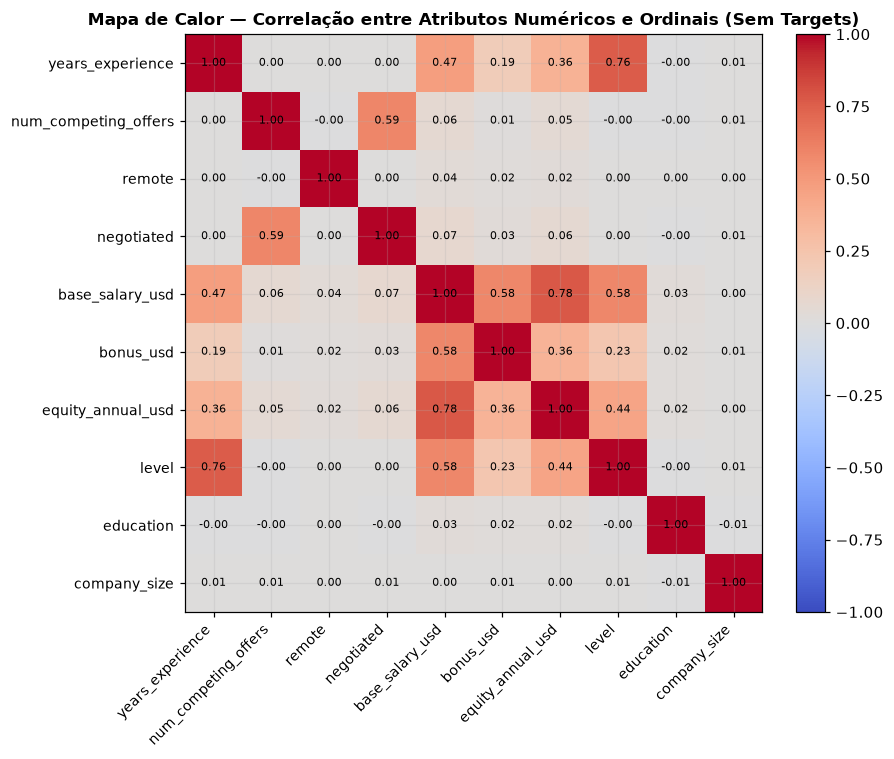

In [35]:
# Definição das colunas de entrada (SEM employee_id, total_comp_usd e high_earner!)
cols_ordinais = ['level', 'education', 'company_size']
cols_numericas = [
    'years_experience', 'num_competing_offers', 'remote',
    'negotiated', 'base_salary_usd', 'bonus_usd', 'equity_annual_usd'
]
cols_nominais = ['company_tier', 'location', 'specialization']
features_modelo = cols_ordinais + cols_numericas + cols_nominais

# Ordenação explícita dos atributos qualitativos ordinais
ordem_level = ['L3_entry', 'L4', 'L5_senior', 'L6_staff', 'L7_principal']
ordem_education = ['self_taught', 'bootcamp', 'bachelors', 'masters', 'phd']
ordem_size = ['<50', '50-500', '500-5k', '5k-50k', '>50k']

def criar_preprocessador(scaler_cls):
    return ColumnTransformer(
        transformers=[
            ('ord', Pipeline([
                ('enc', OrdinalEncoder(
                    categories=[ordem_level, ordem_education, ordem_size],
                    handle_unknown='use_encoded_value',
                    unknown_value=-1
                )),
                ('scl', scaler_cls())
            ]), cols_ordinais),
            ('num', scaler_cls(), cols_numericas),
            ('nom', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cols_nominais),
        ],
        remainder='drop'
    )

prep_zscore = criar_preprocessador(StandardScaler)
prep_robust = criar_preprocessador(RobustScaler)
prep_minmax = criar_preprocessador(MinMaxScaler)

X_tech_full = prep_zscore.fit_transform(df_clean[features_modelo])
X_tech_full_robust = prep_robust.fit_transform(df_clean[features_modelo])
X_tech_full_minmax = prep_minmax.fit_transform(df_clean[features_modelo])
nomes_features = prep_zscore.get_feature_names_out()

# Extrai exatamente os mesmos 2.000 profissionais da amostra estratificada
idx_amostra = amostra_estratificada.index.to_numpy()
X_tech_sample = X_tech_full[idx_amostra]
X_tech_sample_robust = X_tech_full_robust[idx_amostra]
X_tech_sample_minmax = X_tech_full_minmax[idx_amostra]

print(f'Matriz completa padronizada (Z-score): {X_tech_full.shape}')
print(f'Matriz da amostra estratificada: {X_tech_sample.shape}')

# Mapa de calor de correlação das variáveis numéricas e ordinais codificadas (Aula 04)
enc_ord_vis = OrdinalEncoder(categories=[ordem_level, ordem_education, ordem_size])
df_corr = df_clean[cols_numericas].copy()
df_corr[cols_ordinais] = enc_ord_vis.fit_transform(df_clean[cols_ordinais])
corr_mat = df_corr.corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_mat, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_mat.columns)))
ax.set_yticks(range(len(corr_mat.columns)))
ax.set_xticklabels(corr_mat.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(corr_mat.columns, fontsize=9)
for i in range(len(corr_mat)):
    for j in range(len(corr_mat)):
        ax.text(j, i, f'{corr_mat.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7, color='black')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.title('Mapa de Calor — Correlação entre Atributos Numéricos e Ordinais (Sem Targets)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

> 📌 **Análise do Pré-processamento e das Correlações:**  
> - O `ColumnTransformer` produziu a matriz `X_tech_full` com dimensões `(28000, 33)` (10 colunas ordinais/numéricas padronizadas + 23 colunas *one-hot* nominais) e `X_tech_sample` com `(2000, 33)`.  
> - O mapa de calor evidencia fortes correlações positivas entre `base_salary_usd` e `equity_annual_usd` (`0,78`), `years_experience` e `level` (`0,76`), `num_competing_offers` e `negotiated` (`0,59`), além de `base_salary_usd` com `level` (`0,58`) e `bonus_usd` (`0,58`). Já `education`, `company_size` e `remote` apresentam correlação linear próxima de zero (`-0,01` a `0,04`) com os componentes salariais.

---

## 10. Modelagem Particional e Divisiva na Base Completa (*N = 28.000*): `K-Means` vs. `Bisecting K-Means`

Aplicamos `KMeans` e `BisectingKMeans` para $k \in \{2, 3, \dots, 10\}$ sobre toda a população (`X_tech_full`), demonstrando a escalabilidade desses algoritmos e avaliando a técnica do joelho juntamente com **Silhouette**, **Calinski-Harabasz** e **Davies-Bouldin**. *(Nota: para viabilidade computacional do Silhouette em $28.000$ pontos, utilizamos `sample_size=5000` determinístico com `RANDOM_STATE = 42`.)*

,Algoritmo,k,Inercia_WCSS,Silhouette,Calinski_Harabasz,Davies_Bouldin
0,K-Means,2,298452.9105,0.1810,4969.2020,2.1766
1,Bisecting K-Means,2,298453.1030,0.1812,4969.1872,2.1760
2,K-Means,3,268711.5240,0.1357,4308.8737,2.0903
3,Bisecting K-Means,3,271105.1632,0.1187,4147.2389,2.1046
4,K-Means,4,252401.0432,0.1267,3661.1485,2.1280
5,Bisecting K-Means,4,254709.7528,0.1233,3543.3804,2.1198
6,K-Means,5,238499.6020,0.1238,3313.7425,2.0988
7,Bisecting K-Means,5,240843.7245,0.1138,3213.3737,2.1140
8,K-Means,6,227538.5633,0.1259,3048.3091,2.0261
9,Bisecting K-Means,6,231851.0927,0.1166,2887.4674,2.1766


K-Means (N=28.000) -> Melhor k por Silhouette: 2 | Calinski-Harabasz: 2 | Davies-Bouldin: 6
Bisecting K-Means (N=28.000) -> Melhor k por Silhouette: 2 | Calinski-Harabasz: 2 | Davies-Bouldin: 3


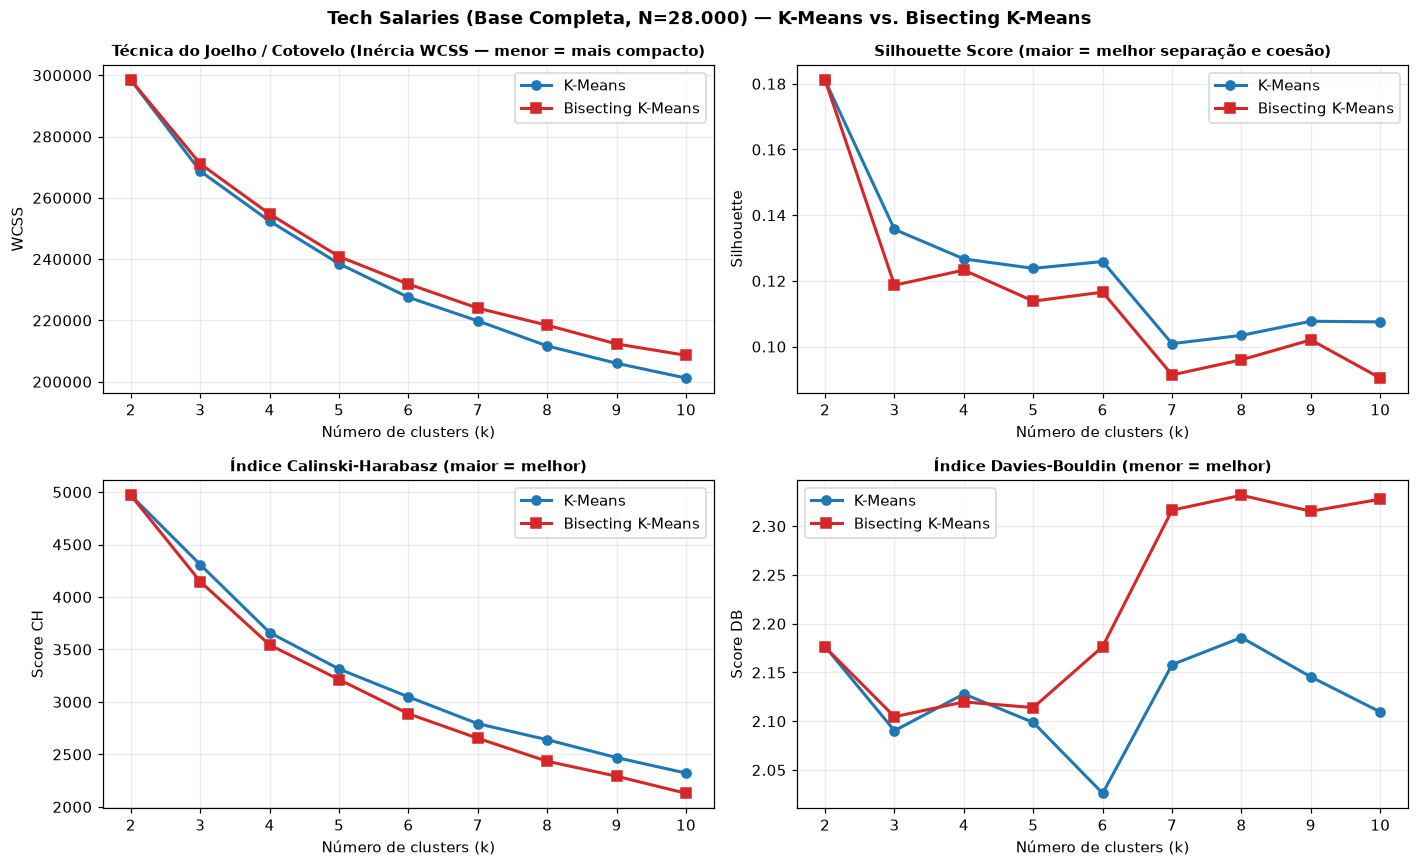

In [36]:
ks_tech = range(2, 11)
df_res_tech_full = rodar_varredura_k(X_tech_full, ks_tech, sample_size=5000, random_state=RANDOM_STATE)

display(df_res_tech_full.round(4))

for alg in ['K-Means', 'Bisecting K-Means']:
    sub = df_res_tech_full[df_res_tech_full['Algoritmo'] == alg]
    k_sil = int(sub.loc[sub['Silhouette'].idxmax(), 'k'])
    k_ch = int(sub.loc[sub['Calinski_Harabasz'].idxmax(), 'k'])
    k_db = int(sub.loc[sub['Davies_Bouldin'].idxmin(), 'k'])
    print(f'{alg} (N=28.000) -> Melhor k por Silhouette: {k_sil} | Calinski-Harabasz: {k_ch} | Davies-Bouldin: {k_db}')

plotar_curvas_k(
    df_res_tech_full,
    ks_tech,
    'Tech Salaries (Base Completa, N=28.000) — K-Means vs. Bisecting K-Means'
)

> 📌 **Leitura da Parametrização em *Tech Salaries* (Base Completa, N = 28.000):**  
> - **Sensibilidade dos Critérios Internos (Reflexão da Atividade):** Diferentemente da *Iris* (onde todos os índices convergiram para $k=2$), em *Tech Salaries* observa-se clara divergência entre critérios: **Silhouette** (`0,1810` no `K-Means`; `0,1812` no `Bisecting`) e **Calinski-Harabasz** (`4.969,20` e `4.969,19`) apontam **$k=2$**, enquanto o **Davies-Bouldin** atinge seu mínimo (melhor valor) em **$k=6$** para o `K-Means` (`2,0261`, contra `2,1766` em $k=2$) e em **$k=3$** para o `Bisecting K-Means` (`2,1046`).  
> - **Curva do Joelho (WCSS):** A redução de inércia de $k=2$ (`298.452,91`) para $k=3$ (`268.711,52`) e $k=4$ (`252.401,04`) suaviza progressivamente sem um ângulo único abrupto, típico de dados multidimensionais contínuos combinados com variáveis categóricas.  
> - **K-Means vs. Bisecting K-Means:** Para $k \ge 3$, o `K-Means` obtém consistentemente menor WCSS, maior Silhouette e maior Calinski-Harabasz que o `Bisecting K-Means` (por exemplo, em $k=3$: Silhouette `0,1357` vs. `0,1187` e WCSS `268.711,52` vs. `271.105,16`), pois reajusta todos os centróides simultaneamente.

---

## 11. Agrupamento Hierárquico Aglomerativo (`Linkage Family`) e Comparativo Justo (*n = 2.000*)

Utilizando a **amostra estratificada (`X_tech_sample`, $n=2.000$)**, aplicamos `scipy.cluster.hierarchy.linkage` com os métodos **Single**, **Complete**, **Average** e **Ward**, calculando a **Correlação Cofenética** e exibindo os **dendrogramas truncados** (últimas 30 fusões para nitidez visual). Em seguida, avaliamos todos os algoritmos lado a lado exatamente sobre os mesmos $2.000$ registros.

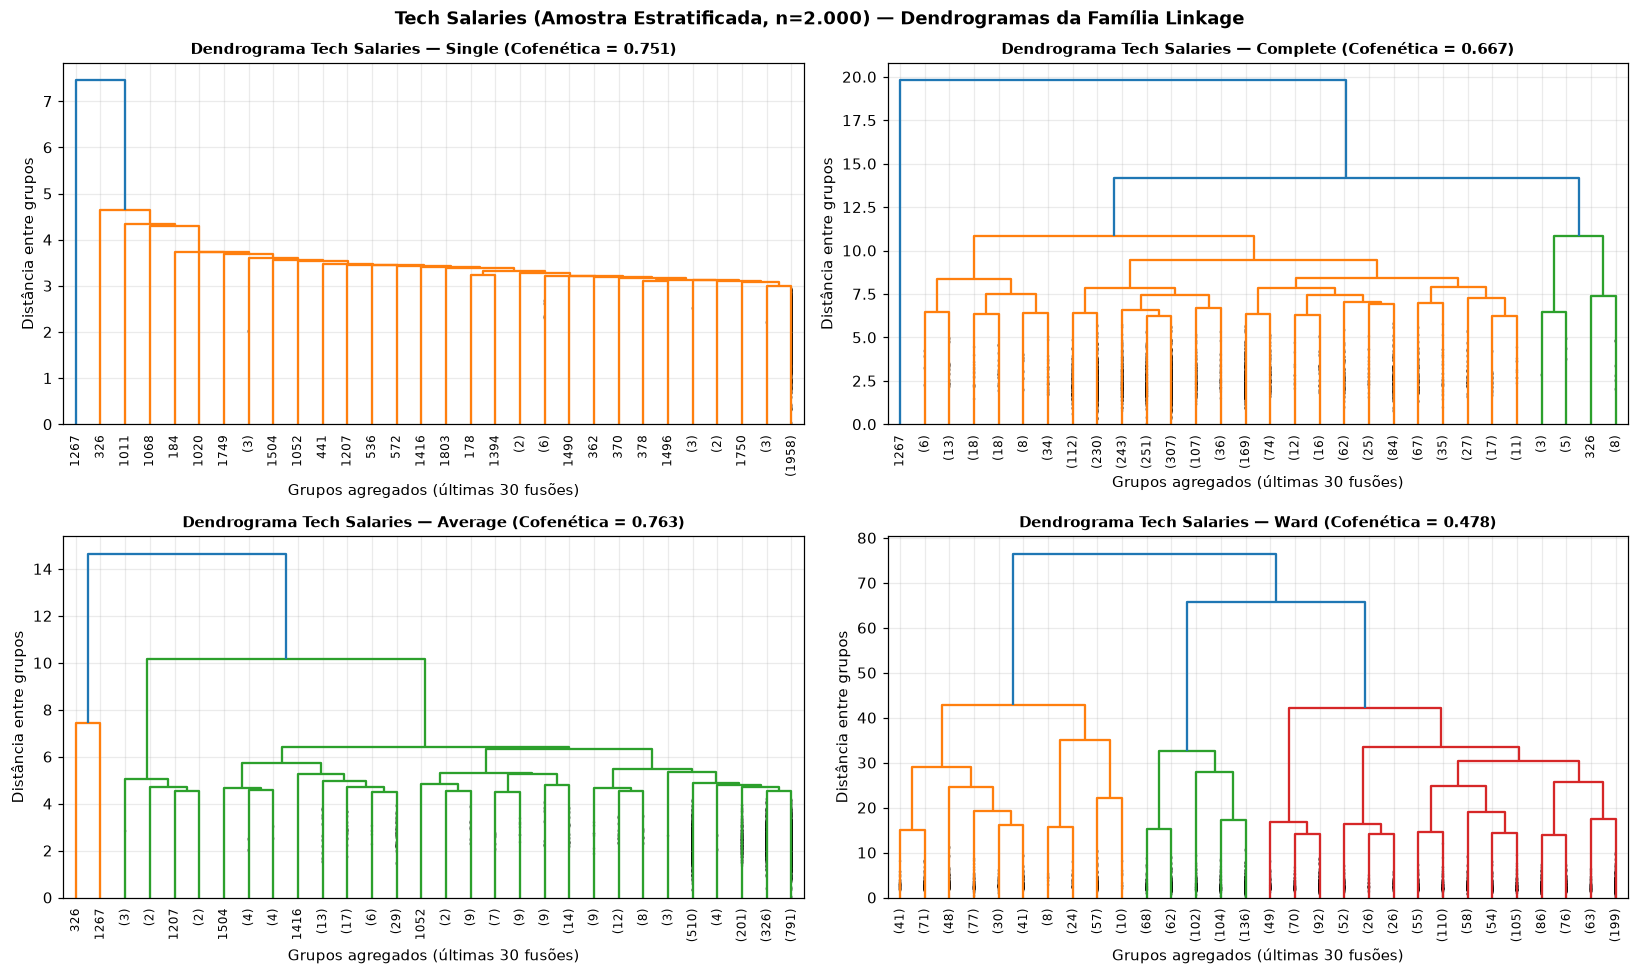

In [37]:
dist_tech = pdist(X_tech_sample, metric='euclidean')

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
lin_tech = {}

for ax, metodo in zip(axes.flat, metodos_linkage):
    Z = linkage(X_tech_sample, method=metodo)
    coph_corr, _ = cophenet(Z, dist_tech)
    lin_tech[metodo] = Z

    dendrogram(
        Z,
        truncate_mode='lastp',
        p=30,
        leaf_rotation=90,
        leaf_font_size=8,
        show_contracted=True,
        ax=ax
    )
    ax.set_title(f'Dendrograma Tech Salaries — {metodo.capitalize()} (Cofenética = {coph_corr:.3f})', fontsize=10, fontweight='bold')
    ax.set_xlabel('Grupos agregados (últimas 30 fusões)')
    ax.set_ylabel('Distância entre grupos')

plt.suptitle('Tech Salaries (Amostra Estratificada, n=2.000) — Dendrogramas da Família Linkage', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

> 📌 **Análise dos Dendrogramas em *Tech Salaries* (Amostra n = 2.000):**  
> - **Detecção de *Outliers* na Hierarquia (Aula de Agrupamento Hierárquico, slides 7–8):** Os ramos solitários no topo dos dendrogramas **Single (Cofenética = `0,751`)**, **Complete (`0,667`)** e **Average (`0,763`)** expõem os profissionais mais discrepantes da amostra (como os índices `1267` e `326`), que se unem ao restante apenas em distâncias muito elevadas (`~7,4` no Single, `~20,0` no Complete e `~14,7` no Average).  
> - **Chaining Effect (`single-linkage`):** O padrão em "escada" evidencia o encadeamento progressivo que funde quase toda a amostra (`1.958` registros em um único ramo principal) antes de incorporar os casos extremos.  
> - **Equilíbrio Estrutural (`ward`, Cofenética = `0,478`):** Embora tenha menor correlação cofenética por priorizar variância mínima intra-cluster (e não distâncias originais), o método de Ward evita grupos degenerados e produz a árvore mais balanceada da família `Linkage`.

A seguir, comparamos diretamente **K-Means**, **Bisecting K-Means** e os quatro métodos **Linkage** sobre exatamente os mesmos $2.000$ registros (`X_tech_sample`), além de testar a sensibilidade à escolha da normalização (**Z-score** vs. **RobustScaler** vs. **Min-Max**).

Comparativo de Desempenho e Equilíbrio dos Grupos (k = 2, 3, 4 e 5):


,Algoritmo,k,Silhouette,Calinski_Harabasz,Davies_Bouldin,Menor_Cluster,Maior_Cluster
0,K-Means,2,0.1792,362.0331,2.1688,605,1395
1,Bisecting K-Means,2,0.1792,362.0331,2.1688,605,1395
2,Linkage (single),2,0.7228,24.3602,0.1957,1,1999
3,Linkage (complete),2,0.7228,24.3602,0.1957,1,1999
4,Linkage (average),2,0.6675,32.5823,0.5037,2,1998
5,Linkage (ward),2,0.1869,267.6513,2.2623,407,1593
6,K-Means,3,0.1363,311.3488,2.0687,467,1049
7,Bisecting K-Means,3,0.1192,298.1145,2.0824,397,998
8,Linkage (single),3,0.5820,17.4410,0.2650,1,1998
9,Linkage (complete),3,0.4953,53.2858,0.8848,1,1982


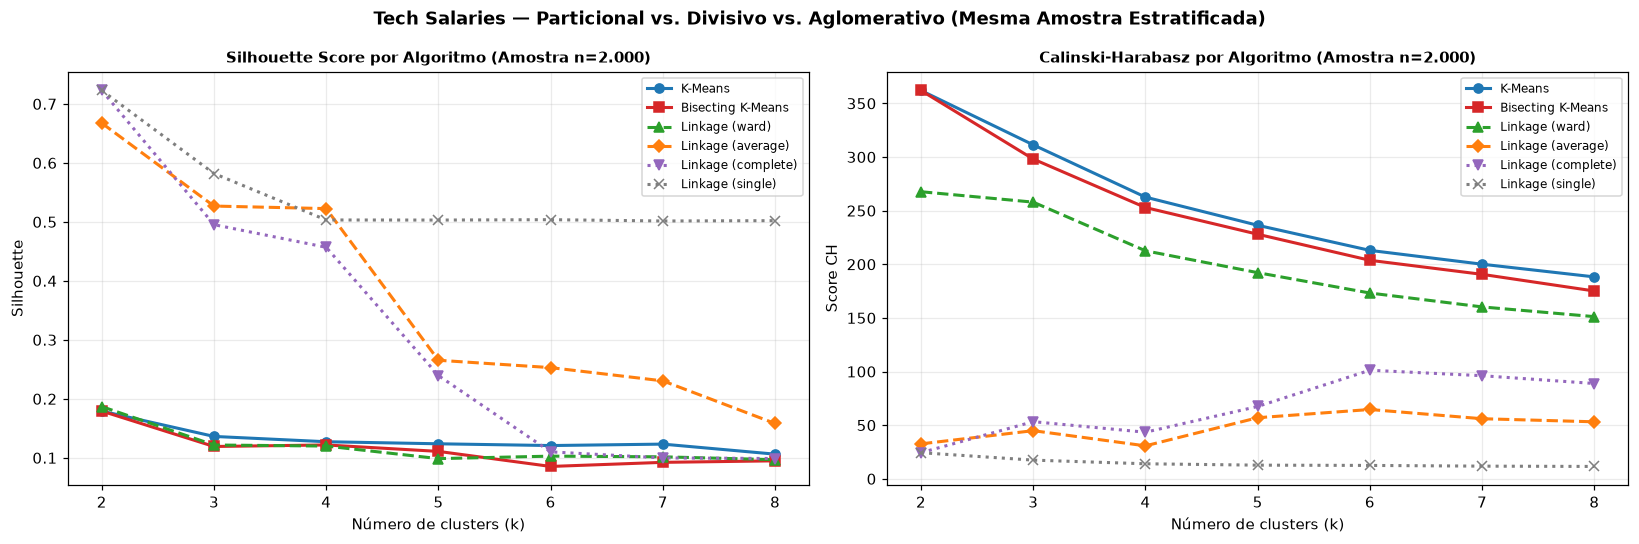


Sensibilidade à Normalização no K-Means (Z-score vs. RobustScaler vs. Min-Max):


,k,Sil_ZScore,Sil_Robust,Sil_MinMax,CH_ZScore,CH_Robust,CH_MinMax
0,2,0.1792,0.5608,0.0820,362.0331,758.7573,152.4449
1,3,0.1363,0.2394,0.0800,311.3488,607.3255,136.6708
2,4,0.1273,0.2231,0.0693,262.6236,532.9026,125.1605
3,5,0.1238,0.1200,0.1232,236.3622,465.3813,119.9974


In [38]:
ks_comp = range(2, 9)
comp_algoritmos = []

for k in ks_comp:
    lbl_km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_tech_sample)
    lbl_bkm = BisectingKMeans(
        n_clusters=k, n_init=10, bisecting_strategy='biggest_inertia', random_state=RANDOM_STATE
    ).fit_predict(X_tech_sample)

    modelos_eval = [('K-Means', lbl_km), ('Bisecting K-Means', lbl_bkm)]
    for m in metodos_linkage:
        modelos_eval.append((f'Linkage ({m})', fcluster(lin_tech[m], t=k, criterion='maxclust')))

    for nome, labels in modelos_eval:
        sil, ch, db = avaliar_particao(X_tech_sample, labels)
        counts = pd.Series(labels).value_counts()
        comp_algoritmos.append({
            'Algoritmo': nome,
            'k': k,
            'Silhouette': sil,
            'Calinski_Harabasz': ch,
            'Davies_Bouldin': db,
            'Menor_Cluster': int(counts.min()),
            'Maior_Cluster': int(counts.max()),
        })

df_comp_sample = pd.DataFrame(comp_algoritmos)
print('Comparativo de Desempenho e Equilíbrio dos Grupos (k = 2, 3, 4 e 5):')
display(df_comp_sample[df_comp_sample['k'].isin([2, 3, 4, 5])].round(4))

# Plot comparativo entre algoritmos (Silhouette e Calinski-Harabasz)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
estilos = {
    'K-Means': ('#1f77b4', 'o', '-'),
    'Bisecting K-Means': ('#d62728', 's', '-'),
    'Linkage (ward)': ('#2ca02c', '^', '--'),
    'Linkage (average)': ('#ff7f0e', 'D', '--'),
    'Linkage (complete)': ('#9467bd', 'v', ':'),
    'Linkage (single)': ('#7f7f7f', 'x', ':'),
}

for alg, (cor, marc, ls) in estilos.items():
    sub = df_comp_sample[df_comp_sample['Algoritmo'] == alg]
    axes[0].plot(sub['k'], sub['Silhouette'], color=cor, marker=marc, linestyle=ls, linewidth=2, label=alg)
    axes[1].plot(sub['k'], sub['Calinski_Harabasz'], color=cor, marker=marc, linestyle=ls, linewidth=2, label=alg)

axes[0].set_title('Silhouette Score por Algoritmo (Amostra n=2.000)', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Silhouette')
axes[0].set_xticks(list(ks_comp))
axes[0].legend(fontsize=8)

axes[1].set_title('Calinski-Harabasz por Algoritmo (Amostra n=2.000)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Score CH')
axes[1].set_xticks(list(ks_comp))
axes[1].legend(fontsize=8)

plt.suptitle('Tech Salaries — Particional vs. Divisivo vs. Aglomerativo (Mesma Amostra Estratificada)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Teste de sensibilidade da normalização: Z-score vs. RobustScaler vs. Min-Max (Aula 01)
sens_norm = []
for k in [2, 3, 4, 5]:
    l_z = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_tech_sample)
    l_r = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_tech_sample_robust)
    l_m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_tech_sample_minmax)
    sil_z, ch_z, db_z = avaliar_particao(X_tech_sample, l_z)
    sil_r, ch_r, db_r = avaliar_particao(X_tech_sample_robust, l_r)
    sil_m, ch_m, db_m = avaliar_particao(X_tech_sample_minmax, l_m)
    sens_norm.append({
        'k': k,
        'Sil_ZScore': sil_z,
        'Sil_Robust': sil_r,
        'Sil_MinMax': sil_m,
        'CH_ZScore': ch_z,
        'CH_Robust': ch_r,
        'CH_MinMax': ch_m,
    })

print('\nSensibilidade à Normalização no K-Means (Z-score vs. RobustScaler vs. Min-Max):')
display(pd.DataFrame(sens_norm).round(4))

> 📌 **Comparativo Crítico dos Algoritmos em *Tech Salaries* (Amostra n = 2.000):**  
> - **Armadilha do Silhouette em Grupos Degenerados:** Em $k=2$, `Linkage (single)` e `Linkage (complete)` atingiram **Silhouette = `0,7228`** (e `average` `0,6675`) porque **isolaram apenas `1` ou `2` *outliers* extremos** enquanto colocaram `1.999` / `1.998` profissionais no outro grupo! O índice **Calinski-Harabasz** denuncia imediatamente a inutilidade dessa partição para segmentação (`CH = 24,36` e `32,58`). Mesmo em $k=5$, os três métodos ainda mantêm `Menor_Cluster = 1`.  
> - **Desempenho Superior das Partições Balanceadas:** **`K-Means`** e **`Bisecting K-Means`** lideram em **Calinski-Harabasz** em toda a faixa avaliada (em $k=2$: **`CH = 362,03`** com grupos de **`605` e `1.395`** pessoas, superando `Ward` com `CH = 267,65` e grupos de `407` vs. `1.593`), além de manter melhor **Davies-Bouldin** (`2,1688` vs. `2,2623` no Ward). Para $k \ge 3$, o `K-Means` supera consistentemente tanto o `Bisecting K-Means` quanto o `Ward`.  
> - **Impacto da Normalização (Aula 01):** No teste de sensibilidade em $k=2$, **`RobustScaler`** elevou Silhouette para `0,5608` e CH para `758,76` (por escalar pela mediana/IQR, destacando fortemente a cauda salarial superior), **`StandardScaler` (Z-score)** manteve equilíbrio entre variáveis contínuas e binárias (`Sil = 0,1792`, `CH = 362,03`), e **`MinMaxScaler`** sofreu forte compressão pelo valor máximo (`Sil = 0,0820`, `CH = 152,44`).

---

## 12. Projeção PCA 2D, Descrição dos Clusters e Avaliação Indireta dos Rótulos (*Tech Salaries*)

Selecionamos o número ótimo de clusters para o `K-Means` diretamente a partir do **Silhouette Score** na base completa (`k_otimo_tech`), ajustamos os modelos finais (`K-Means` e `Bisecting K-Means`) em toda a população ($N=28.000$) e projetamos os dados em 2 dimensões via **PCA** para comparar os clusters descobertos com uma variável discreta de carreira (`level`) e com o alvo omitido (`high_earner`, revelado somente agora!).

Número ótimo de clusters selecionado pelo Silhouette (K-Means): k = 2
Variância explicada pelo PCA 2D (Tech Salaries): PC1 = 23.71% | PC2 = 12.71% | Total = 36.42%

Top 8 atributos com maior contribuição em PC1:


,PC1,PC2
num__base_salary_usd,0.526,0.013
ord__level,0.460,-0.097
num__equity_annual_usd,0.458,0.016
num__years_experience,0.419,-0.096
num__bonus_usd,0.338,0.003
num__negotiated,0.052,0.700
num__num_competing_offers,0.047,0.700
nom__company_tier_mid_tier,-0.046,0.002


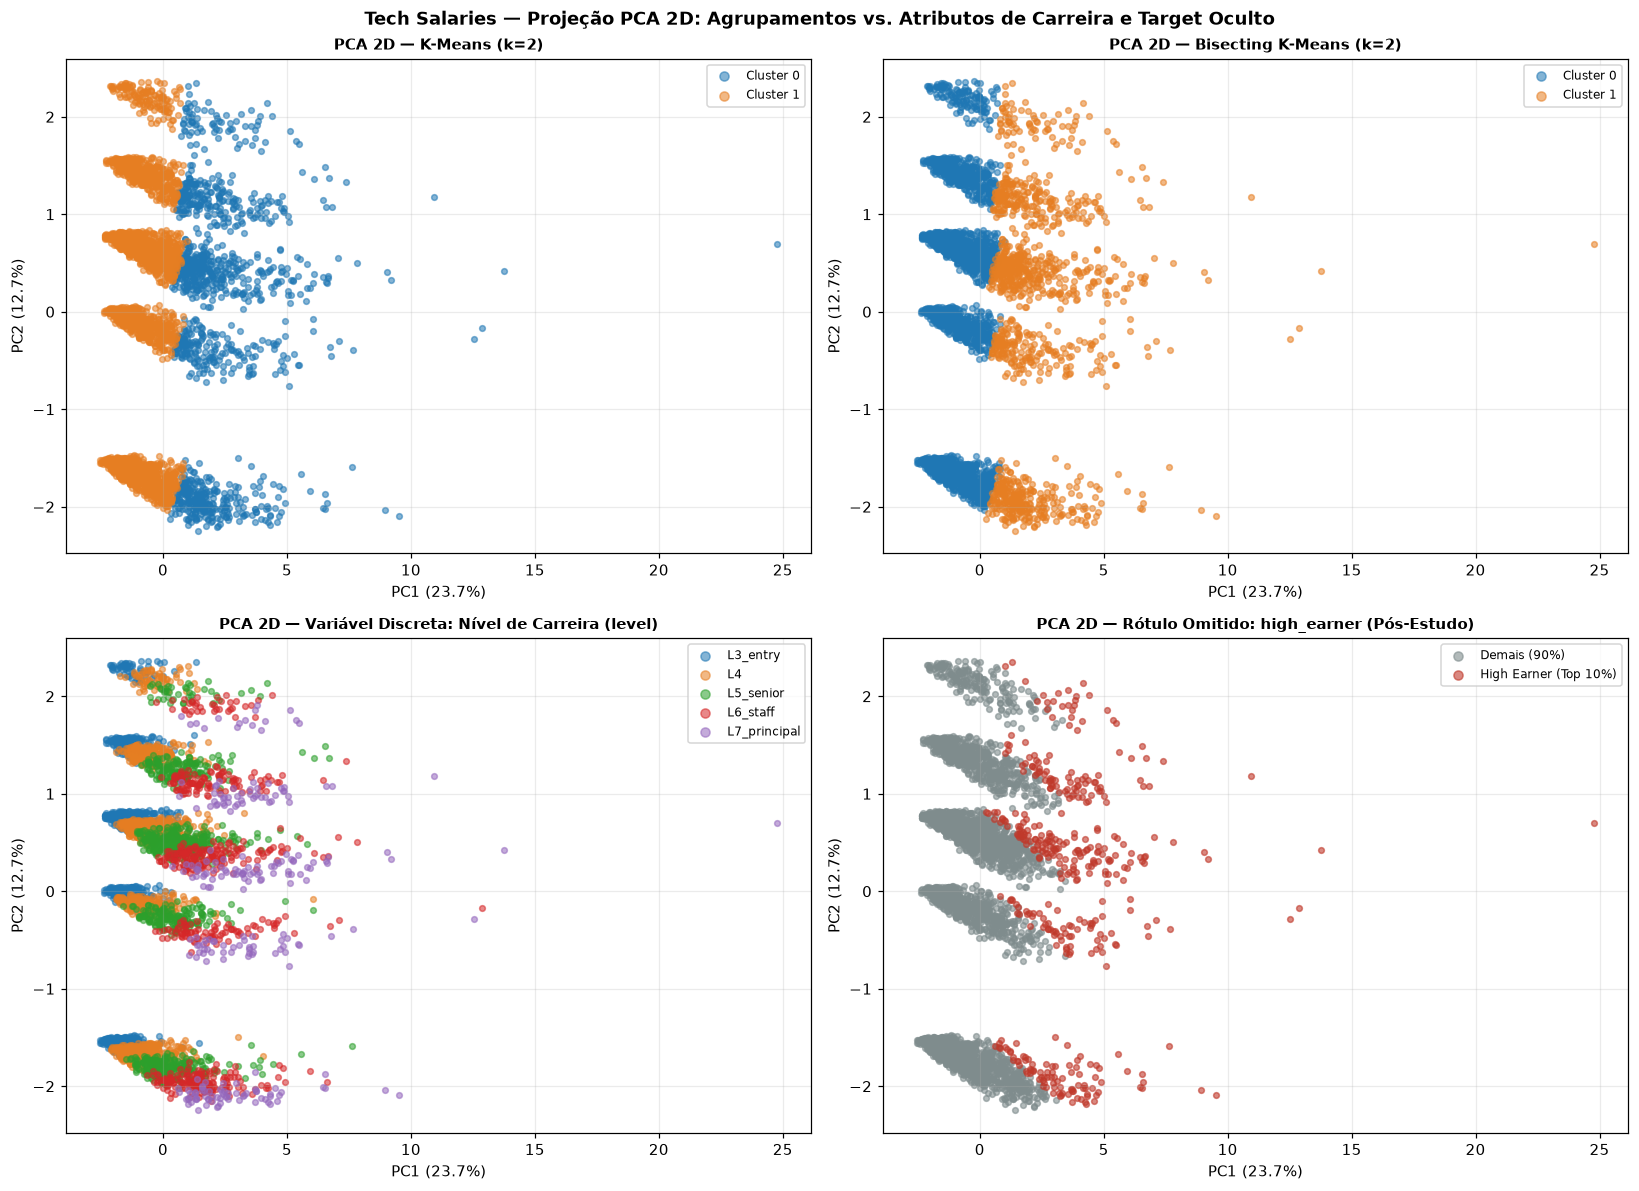

In [39]:
# Seleção automática do k ótimo pelo maior Silhouette Score no K-Means (ml-best-practices)
sub_km_full = df_res_tech_full[df_res_tech_full['Algoritmo'] == 'K-Means']
k_otimo_tech = int(sub_km_full.loc[sub_km_full['Silhouette'].idxmax(), 'k'])
print(f'Número ótimo de clusters selecionado pelo Silhouette (K-Means): k = {k_otimo_tech}')

# Ajuste final dos modelos particional e divisivo na base completa (N = 28.000)
km_final = KMeans(n_clusters=k_otimo_tech, n_init=10, random_state=RANDOM_STATE).fit(X_tech_full)
bkm_final = BisectingKMeans(
    n_clusters=k_otimo_tech, n_init=10, bisecting_strategy='biggest_inertia', random_state=RANDOM_STATE
).fit(X_tech_full)

df_clean['cluster_kmeans'] = km_final.labels_
df_clean['cluster_bisecting'] = bkm_final.labels_

# Projeção PCA 2D na base completa (ml-best-practices)
pca_tech = PCA(n_components=2, random_state=RANDOM_STATE)
X_tech_pca = pca_tech.fit_transform(X_tech_full)
var_exp_tech = pca_tech.explained_variance_ratio_ * 100
print(f'Variância explicada pelo PCA 2D (Tech Salaries): PC1 = {var_exp_tech[0]:.2f}% | PC2 = {var_exp_tech[1]:.2f}% | Total = {var_exp_tech.sum():.2f}%')

# Pesos (loadings) dos atributos mais influentes em PC1 e PC2
loadings = pd.DataFrame(pca_tech.components_.T, index=nomes_features, columns=['PC1', 'PC2'])
print('\nTop 8 atributos com maior contribuição em PC1:')
display(loadings.reindex(loadings['PC1'].abs().sort_values(ascending=False).head(8).index).round(3))

# Amostra visual de 4.000 pontos para evitar sobreposição excessiva no gráfico
rng = np.random.default_rng(RANDOM_STATE)
idx_vis = rng.choice(len(df_clean), size=min(4000, len(df_clean)), replace=False)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
paleta_c = ['#1f77b4', '#e67e22', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#17becf']

# Painel 1: Clusters K-Means
for i, c in enumerate(sorted(df_clean['cluster_kmeans'].unique())):
    m = df_clean['cluster_kmeans'].iloc[idx_vis].values == c
    axes[0, 0].scatter(X_tech_pca[idx_vis][m, 0], X_tech_pca[idx_vis][m, 1], s=14, alpha=0.55, color=paleta_c[i % len(paleta_c)], label=f'Cluster {c}')
axes[0, 0].set_title(f'PCA 2D — K-Means (k={k_otimo_tech})', fontsize=10, fontweight='bold')
axes[0, 0].legend(fontsize=8, markerscale=1.6)

# Painel 2: Clusters Bisecting K-Means
for i, c in enumerate(sorted(df_clean['cluster_bisecting'].unique())):
    m = df_clean['cluster_bisecting'].iloc[idx_vis].values == c
    axes[0, 1].scatter(X_tech_pca[idx_vis][m, 0], X_tech_pca[idx_vis][m, 1], s=14, alpha=0.55, color=paleta_c[i % len(paleta_c)], label=f'Cluster {c}')
axes[0, 1].set_title(f'PCA 2D — Bisecting K-Means (k={k_otimo_tech})', fontsize=10, fontweight='bold')
axes[0, 1].legend(fontsize=8, markerscale=1.6)

# Painel 3: Feature discreta de negócio (level)
for i, lv in enumerate(ordem_level):
    m = df_clean['level'].iloc[idx_vis].values == lv
    axes[1, 0].scatter(X_tech_pca[idx_vis][m, 0], X_tech_pca[idx_vis][m, 1], s=14, alpha=0.55, color=paleta_c[i % len(paleta_c)], label=lv)
axes[1, 0].set_title('PCA 2D — Variável Discreta: Nível de Carreira (level)', fontsize=10, fontweight='bold')
axes[1, 0].legend(fontsize=8, markerscale=1.6)

# Painel 4: Rótulo oculto (high_earner — avaliação indireta a posteriori)
for i, (he, nome_he) in enumerate([(0, 'Demais (90%)'), (1, 'High Earner (Top 10%)')]):
    m = targets_ocultos['high_earner'].iloc[idx_vis].values == he
    axes[1, 1].scatter(X_tech_pca[idx_vis][m, 0], X_tech_pca[idx_vis][m, 1], s=14, alpha=0.60, color=['#7f8c8d', '#c0392b'][i], label=nome_he)
axes[1, 1].set_title('PCA 2D — Rótulo Omitido: high_earner (Pós-Estudo)', fontsize=10, fontweight='bold')
axes[1, 1].legend(fontsize=8, markerscale=1.6)

for ax in axes.flat:
    ax.set_xlabel(f'PC1 ({var_exp_tech[0]:.1f}%)')
    ax.set_ylabel(f'PC2 ({var_exp_tech[1]:.1f}%)')

plt.suptitle('Tech Salaries — Projeção PCA 2D: Agrupamentos vs. Atributos de Carreira e Target Oculto', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

> 📌 **Interpretação da Projeção PCA 2D (*Tech Salaries*):**  
> - O **PCA 2D** captura **`36,42%` da variância total** (`PC1 = 23,71%`, `PC2 = 12,71%`), reduzindo as `33` dimensões para visualização clara:  
>   - **Eixo Horizontal (`PC1`):** Governado por **salário base (`0,526`)**, **nível de carreira (`0,460`)**, **equity (`0,458`)**, **experiência (`0,419`)** e **bônus (`0,338`)** — representa diretamente o eixo de *senioridade e intensidade salarial*.  
>   - **Eixo Vertical (`PC2`):** Dominado por **`negotiated` (`0,700`)** e **`num_competing_offers` (`0,700`)** — explicando visualmente as **5 faixas horizontais** distintas no gráfico (combinações de ter negociado e quantidade de ofertas concorrentes `0` a `3`).  
> - Os painéis mostram que a fronteira vertical aprendida por `K-Means` e `Bisecting K-Means` (sem rótulos!) alinha-se ao gradiente de `level` (`L3_entry`–`L4` à esquerda; `L6_staff`–`L7_principal` à direita) e isola quase todos os `high_earner` (vermelho) na região positiva de `PC1`.

A seguir, detalhamos o perfil estatístico completo de cada cluster gerado e calculamos as métricas indiretas de alinhamento (**ARI** e **NMI**) contra `high_earner` e `level`.

Perfil Completo dos 2 Clusters (K-Means):


,Qtd,Exp_Media_Anos,Base_Mediano_USD,Bonus_Mediano_USD,Equity_Mediano_USD,Total_Comp_Mediano_USD,Total_Comp_Medio_USD,High_Earner_Pct,Remoto_Pct,Negociou_Pct,Participacao_%,Nivel_Moda,Tier_Moda,Local_Moda,Espec_Moda,Educacao_Moda
cluster_kmeans,,,,,,,,,,,,,,,,
0,8198,11.81,220850.0,41700.0,125500.0,414450.0,472355.05,33.41,28.79,74.02,29.28,L6_staff,faang,sf_bay,backend,bachelors
1,19802,4.19,89800.0,14300.0,41600.0,156900.0,172854.19,0.31,25.58,69.50,70.72,L4,mid_tier,europe,backend,bachelors


Concordância K-Means vs. Bisecting K-Means (k=2) — ARI: 0.9985
Alinhamento indireto Clusters K-Means vs. high_earner — ARI: 0.2887 | NMI: 0.2663
Alinhamento indireto Clusters K-Means vs. level — ARI: 0.2102 | NMI: 0.3059


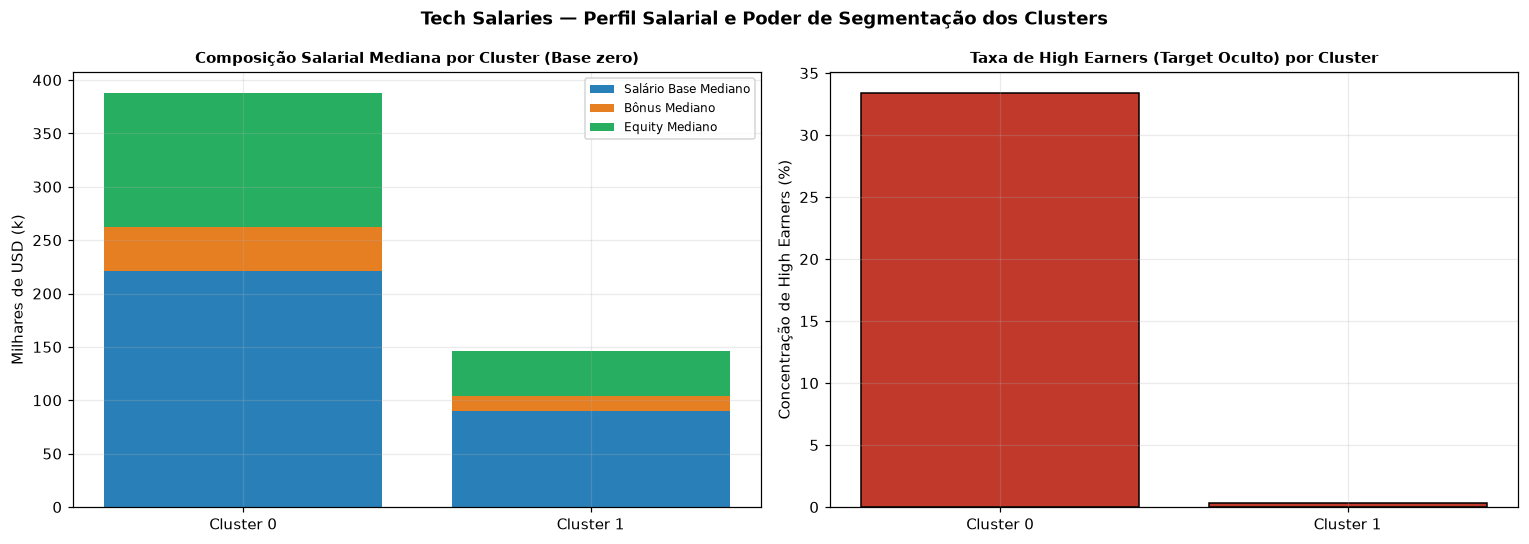

In [40]:
# Perfil estatístico detalhado dos clusters (incluindo targets revelados apenas a posteriori)
perfil_num = df_clean.groupby('cluster_kmeans').agg(
    Qtd=('employee_id', 'count'),
    Exp_Media_Anos=('years_experience', 'mean'),
    Base_Mediano_USD=('base_salary_usd', 'median'),
    Bonus_Mediano_USD=('bonus_usd', 'median'),
    Equity_Mediano_USD=('equity_annual_usd', 'median'),
    Total_Comp_Mediano_USD=('total_comp_usd', 'median'),
    Total_Comp_Medio_USD=('total_comp_usd', 'mean'),
    High_Earner_Pct=('high_earner', lambda s: s.mean() * 100),
    Remoto_Pct=('remote', lambda s: s.mean() * 100),
    Negociou_Pct=('negotiated', lambda s: s.mean() * 100),
).round(2)
perfil_num['Participacao_%'] = (perfil_num['Qtd'] / len(df_clean) * 100).round(2)

perfil_cat = df_clean.groupby('cluster_kmeans').agg(
    Nivel_Moda=('level', lambda s: s.mode().iloc[0]),
    Tier_Moda=('company_tier', lambda s: s.mode().iloc[0]),
    Local_Moda=('location', lambda s: s.mode().iloc[0]),
    Espec_Moda=('specialization', lambda s: s.mode().iloc[0]),
    Educacao_Moda=('education', lambda s: s.mode().iloc[0]),
)

perfil_completo = pd.concat([perfil_num, perfil_cat], axis=1)
print(f'Perfil Completo dos {k_otimo_tech} Clusters (K-Means):')
display(perfil_completo)

# Concordância entre particional e divisivo + avaliação indireta contra rótulos omitidos
print(f"Concordância K-Means vs. Bisecting K-Means (k={k_otimo_tech}) — ARI: {adjusted_rand_score(df_clean['cluster_kmeans'], df_clean['cluster_bisecting']):.4f}")
print(f"Alinhamento indireto Clusters K-Means vs. high_earner — ARI: {adjusted_rand_score(targets_ocultos['high_earner'], df_clean['cluster_kmeans']):.4f} | NMI: {normalized_mutual_info_score(targets_ocultos['high_earner'], df_clean['cluster_kmeans']):.4f}")
print(f"Alinhamento indireto Clusters K-Means vs. level — ARI: {adjusted_rand_score(df_clean['level'], df_clean['cluster_kmeans']):.4f} | NMI: {normalized_mutual_info_score(df_clean['level'], df_clean['cluster_kmeans']):.4f}")

# Gráficos de negócio: Composição Salarial Mediana e Concentração de High Earners
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x_c = np.arange(len(perfil_completo.index))
base_k = perfil_completo['Base_Mediano_USD'] / 1000
bonus_k = perfil_completo['Bonus_Mediano_USD'] / 1000
eq_k = perfil_completo['Equity_Mediano_USD'] / 1000

axes[0].bar(x_c, base_k, color='#2980b9', label='Salário Base Mediano')
axes[0].bar(x_c, bonus_k, bottom=base_k, color='#e67e22', label='Bônus Mediano')
axes[0].bar(x_c, eq_k, bottom=base_k + bonus_k, color='#27ae60', label='Equity Mediano')
axes[0].set_xticks(x_c)
axes[0].set_xticklabels([f'Cluster {c}' for c in perfil_completo.index])
axes[0].set_ylabel('Milhares de USD (k)')
axes[0].set_title('Composição Salarial Mediana por Cluster (Base zero)', fontsize=10, fontweight='bold')
axes[0].legend(fontsize=8)

axes[1].bar(x_c, perfil_completo['High_Earner_Pct'], color='#c0392b', edgecolor='black')
axes[1].set_xticks(x_c)
axes[1].set_xticklabels([f'Cluster {c}' for c in perfil_completo.index])
axes[1].set_ylabel('Concentração de High Earners (%)')
axes[1].set_ylim(bottom=0)
axes[1].set_title('Taxa de High Earners (Target Oculto) por Cluster', fontsize=10, fontweight='bold')

plt.suptitle('Tech Salaries — Perfil Salarial e Poder de Segmentação dos Clusters', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

> 📌 **Descrição dos Perfis (Personas) Descobertos pelo `K-Means` ($k=2$):**  
> - **Cluster 0 — *Elite Sênior & Big Tech* (`8.198` profissionais | `29,28%` da base):**  
>   - **Perfil típico:** Experiência média de **`11,81` anos**, senioridade modal **`L6_staff`**, concentrado em empresas **`faang`** e polo **`sf_bay`** (`backend`, graduação `bachelors`), com **`74,02%`** de negociação ativa e **`28,79%`** em trabalho remoto.  
>   - **Pacote salarial mediano:** Base **\$220.850**, Bônus **\$41.700** e Equity **\$125.500**, totalizando **`total_comp_usd` mediano de \$414.450** (média **\$472.355,05**).  
> - **Cluster 1 — *Base Júnior/Plena & Mercado Padrão* (`19.802` profissionais | `70,72%` da base):**  
>   - **Perfil típico:** Experiência média de **`4,19` anos**, senioridade modal **`L4`**, predominância em empresas **`mid_tier`** e mercado **`europe`** (`69,50%` negociaram; `25,58%` remotos).  
>   - **Pacote salarial mediano:** Base **\$89.800**, Bônus **\$14.300** e Equity **\$41.600**, totalizando **`total_comp_usd` mediano de \$156.900** (média **\$172.854,19**).  
> - **Validação Indireta Pós-Modelagem e Concordância:** `K-Means` e `Bisecting K-Means` atingiram concordância quase perfeita em $k=2$ (**ARI = `0,9985`**). Sem jamais enxergar os alvos, o Cluster 0 concentrou **`33,41%` de `high_earner`** contra apenas **`0,31%`** no Cluster 1 (capturando praticamente todo o decil superior — alinhamento indireto **NMI = `0,2663`** com `high_earner` e **NMI = `0,3059`** com `level`).  
> - **Transparência Metodológica:** Como `base_salary_usd`, `bonus_usd` e `equity_annual_usd` compõem `total_comp_usd`, a fronteira descoberta combina organicamente carreira (`level`, `years_experience`), localização/empresa e estrutura do pacote ofertado.

---

# Parte III — Síntese Final da Atividade

### Q&A

- **1. Como os algoritmos se comportam na base *Iris* (2 vs. 3 clusters sem ver os rótulos)?**  
  Embora a base *Iris* possua `3` espécies reais (`50` flores cada), sua geometria padronizada (capturada em `95,81%` pelo PCA 2D) apresenta *Iris setosa* isolada e *versicolor*/*virginica* formando uma única nuvem contínua. Sem ver `species`, todos os critérios internos apontaram **$k=2$** (`Silhouette = 0,5818`, `CH = 251,35`, `DB = 0,5933`), separando exatamente `50/50` *setosa* das `100` demais flores (`NMI = 0,7337`). Ao explorar $k=3$ na avaliação posterior, `K-Means` obteve o melhor alinhamento com as classes reais (`ARI = 0,6201`), seguido de perto por `Ward Linkage` (`0,6153`) e `Bisecting K-Means` (`0,6101`).

- **2. Como o `K-Means` se comporta em relação a um corte no `Bisecting K-Means`?**  
  Em $k=2$, ambos realizam praticamente a mesma bipartição (idênticos na *Iris*, com WCSS `222,3617`; e concordância **ARI = `0,9985`** em *Tech Salaries*, WCSS `298.452,91` vs. `298.453,10`). Para $k \ge 3$, o `Bisecting K-Means` (`biggest_inertia`) fixa os limites das divisões anteriores e fragmenta apenas o grupo de maior SSE, resultando em inércia e separação ligeiramente piores que o `K-Means` (ex.: em *Tech Salaries* $k=3$, `K-Means` atinge Silhouette `0,1357` e WCSS `268.711,52` contra `0,1187` e `271.105,16` do `Bisecting K-Means`; na *Iris* $k=4$, `114,09` vs. `124,68`), embora preserve a estrutura hierárquica aninhada.

- **3. O joelho (*elbow*) é sensível à escolha do critério de validação interna?**  
  Sim. Na base *Iris*, todos os índices convergiram para $k=2$, mas a curva WCSS ainda sugeria um joelho secundário em $k=3$ (`222,36` $\to$ `139,82`). Já em *Tech Salaries* ($N=28.000$), a sensibilidade ficou explícita: **Silhouette** (`0,1810`) e **Calinski-Harabasz** (`4.969,20`) indicaram **$k=2$**, enquanto **Davies-Bouldin** apontou **$k=6$** (`2,0261`) no `K-Means` e **$k=3$** (`2,1046`) no `Bisecting K-Means`. Além disso, na amostra estratificada, `Single` e `Complete Linkage` alcançaram Silhouette `0,7228` apenas por isolarem `1` *outlier*, provando que métricas isoladas podem enganar sem análise do balanceamento dos grupos e do `Calinski-Harabasz`.

- **4. Qual algoritmo trouxe melhores resultados nas duas bases e por quê?**  
  O **`K-Means`** trouxe os melhores resultados gerais em ambas as bases. Na *Iris*, liderou em Silhouette (`0,4599`) e alinhamento externo em $k=3$ (`ARI = 0,6201`), com **`Ward Linkage`** (`CH = 222,72`) como melhor alternativa hierárquica. Em *Tech Salaries*, o `K-Means` superou `Bisecting K-Means` e toda a família `Linkage` na amostra estratificada (**CH = `362,03`**, **DB = `2,1688`** e clusters equilibrados de `605` e `1.395` pontos, contra grupos degenerados de `1` vs. `1.999` em `single`/`complete` e `407` vs. `1.593` no `Ward`), além de escalar nativamente para todos os `28.000` registros.

### Data Analysis Key Findings

- **Qualidade e Assimetria de *Tech Salaries*:** Os `28.000` registros possuem `0` nulos e `0` duplicados, com forte assimetria à direita nos salários: `total_comp_usd` tem média **\$260.543,76** vs. mediana **\$203.500,00** e 9º decil ($P_{90}$) de **\$501.410,00** (alinhado ao piso **\$501.500** dos `10,00%` classificados como `high_earner`). Outliers reais por IQR chegam a `11,51%` em `bonus_usd` (`3.224` registros) e foram preservados via padronização.
- **Representatividade da Amostragem Estratificada:** A amostra estratificada por `company_tier` ($n=2.000$) manteve fidelidade à população (ex.: `quant_hft` em `4,90%`, `mid_tier` em `24,05%` vs. `24,04%`, salário base mediano **\$113.900** vs. **\$113.500**), viabilizando a execução justa dos algoritmos `Linkage` ($O(N^2)$).
- **Efeitos de Normalização e Hierarquia:** Na família `Linkage` sobre `Tech Salaries`, `Average` (`0,763`) e `Single` (`0,751`) atingiram maior correlação cofenética, mas falharam na partição por *chaining effect* e isolamento de *outliers*. No `K-Means`, `RobustScaler` elevou o contraste da cauda salarial (`Silhouette = 0,5608`), `StandardScaler` equilibrou atributos numéricos/binários (`0,1792`), e `MinMaxScaler` sofreu compressão (`0,0820`).
- **Segmentação Não-Supervisionada com Forte Significado de Negócio:** Sem ver `total_comp_usd` nem `high_earner`, o `K-Means` ($k=2$) separou **Cluster 0 (*Elite Sênior & Big Tech*, `29,28%`, `11,81` anos médios, moda `L6_staff`/`faang`/`sf_bay`, `total_comp` mediano \$414.450, `33,41%` *high earners*)** e **Cluster 1 (*Júnior/Pleno & Mercado Padrão*, `70,72%`, `4,19` anos médios, moda `L4`/`mid_tier`/`europe`, `total_comp` mediano \$156.900, apenas `0,31%` *high earners*)**.

### Insights or Next Steps

- **Aplicação em Gestão de Talentos e Remuneração:** Utilizar os perfis descobertos para calibrar pacotes competitivos por senioridade e tier (`faang`/`ai_lab`/`quant_hft` vs. `mid_tier`), considerando que `base_salary_usd` e `equity_annual_usd` possuem correlação de `0,78` e que negociação (`negotiated`) e ofertas concorrentes (`num_competing_offers`, $r=0,59$) formam o segundo principal eixo de variação no PCA (`PC2 = 12,71%`).
- **Exploração Analítica Futura:** Testar transformação `log1p` nos componentes monetários combinada a algoritmos de densidade (`DBSCAN`/`HDBSCAN`) ou sub-clusterização interna do Cluster 0 (por exemplo, $k=4$ ou $k=6$, sugerido pelo mínimo de Davies-Bouldin em `2,0261`) para distinguir nichos como `quant_hft` (alto bônus) e `ai_lab`/`faang` (alto *equity*).